# ЛР 2. Логистическая регрессия, деревья, ансамбли и SVM

Укажите `VARIANT` от 1 до 4. Общие задания обязательны; дополнительный блок выбирается по варианту.
После смены варианта перезапустите ядро и выполните notebook заново.

Заполните функции с `TODO`, математические решения и ячейки **Ответ**.
В выводах ссылайтесь на свои числа, графики и объекты; объясняйте спорные или неожиданные результаты.

**Оценивание:** 2 балла — полное корректное выполнение; 8 баллов — успешная защита.

**Автор:**\
**Использование LLM:** какие инструменты и для каких частей работы использованы.

In [6]:
VARIANT = 4
assert VARIANT in (1, 2, 3, 4)

## Служебный код

Выполните ячейки этого раздела. При работе с заданиями их можно свернуть.

In [7]:
from __future__ import annotations

from collections.abc import Callable, Sequence
from dataclasses import dataclass
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.typing import NDArray
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.metrics.pairwise import rbf_kernel as library_rbf
from sklearn.svm import SVC, LinearSVC

try:
    from IPython.display import display
except ImportError:

    def display(value: object) -> None:
        print(value)


FloatVector = Sequence[float] | NDArray[np.float64]
FloatMatrix = Sequence[Sequence[float]] | NDArray[np.float64]
IntVector = Sequence[int] | NDArray[np.int64]
LossKind = Literal["squared_hinge", "huber_hinge"]
Objective = Callable[[NDArray[np.float64]], tuple[float, FloatVector]]


@dataclass
class Epoch:
    step: int
    theta: NDArray[np.float64]
    objective: float
    grad_norm: float


@dataclass(frozen=True)
class StopConfig:
    mode: Literal["gradient", "window"]
    grad_tol: float = 1e-5
    rel_tol: float = 1e-8
    patience: int = 5
    guard_tol: float = 1e-3


@dataclass
class FitResult:
    theta: NDArray[np.float64]
    history: list[Epoch]
    reason: str


@dataclass(frozen=True)
class SvmConfig:
    variant: int
    delta: float
    l2: float
    stop: StopConfig
    max_iter: int
    gamma_focus: float


def svm_config(variant: int) -> SvmConfig:
    parameters = {
        1: (0.25, 0.02, "gradient", 8000, 0.01),
        2: (0.5, 0.05, "window", 3000, 0.1),
        3: (1.0, 0.1, "gradient", 3000, 1.0),
        4: (1.5, 0.2, "window", 3000, 10.0),
    }
    if variant not in parameters:
        raise ValueError("SVM: номер варианта должен быть 1, 2, 3 или 4")
    delta, l2, mode, max_iter, gamma = parameters[variant]
    return SvmConfig(variant, delta, l2, StopConfig(mode), max_iter, gamma)


def record(step: int, theta: FloatVector, value: float, grad: FloatVector) -> Epoch:
    theta, grad = np.asarray(theta, dtype=float), np.asarray(grad, dtype=float)
    if theta.ndim != 1 or theta.shape != grad.shape:
        raise ValueError("theta и gradient должны быть векторами одинаковой формы")
    if (
        not np.isfinite(theta).all()
        or not np.isfinite(value)
        or not np.isfinite(grad).all()
    ):
        raise ValueError("theta, objective и gradient должны быть конечными")
    return Epoch(
        step=step,
        theta=theta.copy(),
        objective=float(value),
        grad_norm=float(np.linalg.norm(grad)),
    )


def safe_step(X: FloatMatrix, curvature: float, l2: float) -> float:
    """Готовая верхняя оценка кривизны по расширенной матрице [X, 1]."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) == 0 or curvature <= 0 or l2 < 0:
        raise ValueError("Нужны непустая матрица X, curvature > 0 и l2 >= 0")
    augmented = np.column_stack((X, np.ones(len(X))))
    bound = curvature * np.linalg.norm(augmented, ord=2) ** 2 / len(X) + l2
    return float(1.0 / bound)


def provided_gd(
    objective: Objective,
    theta0: FloatVector,
    eta: float,
    max_iter: int = 2500,
    grad_tol: float = 1e-3,
    *,
    stop_rule: Callable[[Sequence[Epoch]], bool] | None = None,
) -> FitResult:
    """Готовый GD. stop_rule заменяет grad_tol; max_iter ограничивает число обновлений."""
    if not np.isfinite(eta) or eta <= 0 or max_iter < 0 or grad_tol < 0:
        raise ValueError("Нужны eta > 0, max_iter >= 0 и grad_tol >= 0")
    theta = np.asarray(theta0, dtype=float).copy()
    history: list[Epoch] = []
    reason = "max_iter"
    for step in range(max_iter + 1):
        value, grad = objective(theta)
        history.append(record(step, theta, value, grad))
        stopped = (
            bool(stop_rule(history))
            if stop_rule is not None
            else history[-1].grad_norm <= grad_tol
        )
        if stopped:
            reason = "stop_rule" if stop_rule is not None else "gradient"
            break
        if step < max_iter:
            theta -= eta * np.asarray(grad, dtype=float)
    return FitResult(theta=theta.copy(), history=history, reason=reason)


def margin_step(X: FloatMatrix, l2: float, kind: LossKind, delta: float) -> float:
    """Готовый шаг для двух margin-loss; его вывод в этой работе не требуется."""
    if kind not in ("squared_hinge", "huber_hinge") or delta <= 0:
        raise ValueError("Неизвестная loss или неположительный delta")
    return safe_step(X, 2.0 if kind == "squared_hinge" else 1.0 / delta, l2)


def finite_difference_report(
    objective: Objective, theta: FloatVector, eps: float = 1e-6, limit: int = 12
) -> pd.DataFrame:
    theta = np.asarray(theta, dtype=float)
    if theta.ndim != 1 or len(theta) == 0 or eps <= 0 or limit < 1:
        raise ValueError("Нужны непустой вектор theta, eps > 0 и limit >= 1")
    _, analytic = objective(theta)
    analytic = np.asarray(analytic, dtype=float)
    if analytic.shape != theta.shape:
        raise ValueError("Форма градиента не совпадает с theta")
    rows = []
    for j in np.unique(
        np.linspace(0, len(theta) - 1, min(limit, len(theta)), dtype=int)
    ):
        offset = np.zeros_like(theta)
        offset[j] = eps
        numeric = (objective(theta + offset)[0] - objective(theta - offset)[0]) / (
            2 * eps
        )
        rows.append(
            {
                "coordinate": int(j),
                "analytic": analytic[j],
                "numeric": numeric,
                "abs_error": abs(analytic[j] - numeric),
            }
        )
    return pd.DataFrame(rows)


def binary_metrics(
    y: IntVector, prediction: IntVector, probabilities: FloatVector | None = None
) -> dict[str, float]:
    y, prediction = np.asarray(y), np.asarray(prediction)
    result = {
        "accuracy": float(accuracy_score(y, prediction)),
        "F1": float(f1_score(y, prediction, zero_division=0)),
    }
    if probabilities is not None:
        p = np.asarray(probabilities, dtype=float)
        result["Brier"] = float(np.mean((p - y) ** 2))
        result["log_loss"] = float(
            log_loss(y, np.column_stack((1 - p, p)), labels=[0, 1])
        )
    return result


def _svm_arrays(
    X_train: FloatMatrix, y_train: IntVector, X_valid: FloatMatrix, y_valid: IntVector
) -> tuple[NDArray, NDArray, NDArray, NDArray]:
    X_train, X_valid = (
        np.asarray(X_train, dtype=float),
        np.asarray(X_valid, dtype=float),
    )
    y_train, y_valid = np.asarray(y_train, dtype=int), np.asarray(y_valid, dtype=int)
    if (
        X_train.ndim != 2
        or X_valid.ndim != 2
        or X_train.shape[1] != X_valid.shape[1]
        or y_train.shape != (len(X_train),)
        or y_valid.shape != (len(X_valid),)
        or not len(X_train)
        or not len(X_valid)
    ):
        raise ValueError("Проверьте формы train/validation массивов")
    if (
        not np.array_equal(np.unique(y_train), [0, 1])
        or not np.isin(y_valid, [0, 1]).all()
    ):
        raise ValueError("Нужны бинарные метки 0/1 и оба класса в train")
    return X_train, y_train, X_valid, y_valid


def smoke_margin_loss(variant: int) -> pd.DataFrame:
    """Фиксированные числовые якоря: обе loss, оба класса, активная и нулевая зоны."""
    cfg = svm_config(variant)
    margins = np.array([-1.0, 0.0, 0.5, 0.875, 1.0, 2.0])
    huber_anchors = {
        1: (
            [1.875, 0.875, 0.375, 0.03125, 0.0, 0.0],
            [-1.0, -1.0, -1.0, -0.5, 0.0, 0.0],
        ),
        2: (
            [1.75, 0.75, 0.25, 0.015625, 0.0, 0.0],
            [-1.0, -1.0, -1.0, -0.25, 0.0, 0.0],
        ),
        3: (
            [1.5, 0.5, 0.125, 0.0078125, 0.0, 0.0],
            [-1.0, -1.0, -0.5, -0.125, 0.0, 0.0],
        ),
        4: (
            [1.25, 1 / 3, 1 / 12, 1 / 192, 0.0, 0.0],
            [-1.0, -2 / 3, -1 / 3, -1 / 12, 0.0, 0.0],
        ),
    }
    expected = {
        "squared_hinge": (
            [4.0, 1.0, 0.25, 0.015625, 0.0, 0.0],
            [-4.0, -2.0, -1.0, -0.25, 0.0, 0.0],
        ),
        "huber_hinge": huber_anchors[variant],
    }
    rows = []
    for kind, (wanted_loss, wanted_grad) in expected.items():
        for label in [0, 1]:
            sign = 2 * label - 1
            loss, grad = margin_loss_grad(
                (sign * margins).tolist(), [label] * len(margins), kind, cfg.delta
            )
            loss, grad = np.asarray(loss), np.asarray(grad)
            assert loss.shape == margins.shape and grad.shape == margins.shape, (
                "Нужен результат на каждый объект"
            )
            np.testing.assert_allclose(
                loss, wanted_loss, atol=1e-12, err_msg=f"Якорь loss: {kind}, y={label}"
            )
            np.testing.assert_allclose(
                grad,
                sign * np.asarray(wanted_grad),
                atol=1e-12,
                err_msg=f"Производная должна быть по score: {kind}, y={label}",
            )
            rows.append(
                {
                    "loss": kind,
                    "y": label,
                    "loss(score=0)": float(loss[1]),
                    "d_loss/d_score(score=0)": float(grad[1]),
                    "anchors": "OK",
                }
            )
    return pd.DataFrame(rows)


def run_margin_loss_experiment(variant: int, *, plot: bool = True) -> pd.DataFrame:
    cfg = svm_config(variant)
    margins = np.linspace(-2.0, 2.0, 321)
    rows = []
    for kind in ["squared_hinge", "huber_hinge"]:
        loss, grad = margin_loss_grad(
            margins, np.ones(len(margins), dtype=int), kind, cfg.delta
        )
        rows.append(
            pd.DataFrame(
                {"loss": kind, "margin": margins, "value": loss, "derivative": grad}
            )
        )
    table = pd.concat(rows, ignore_index=True)
    if plot:
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
        for kind, part in table.groupby("loss", sort=False):
            axes[0].plot(part.margin, part.value, label=kind)
            axes[1].plot(part.margin, part.derivative, label=kind)
        axes[0].plot(margins, np.maximum(0.0, 1 - margins), "--", label="hinge")
        for ax, ylabel in zip(axes, ["Loss", "Производная по score при y=1"]):
            ax.set(xlabel="Margin", ylabel=ylabel)
            ax.legend(fontsize=8)
            ax.grid(alpha=0.2)
        fig.suptitle(f"Две margin-loss, delta={cfg.delta}")
        fig.tight_layout()
        plt.show()
    return table


def smoke_svm_objective(variant: int) -> pd.DataFrame:
    cfg = svm_config(variant)
    X, y, theta = [[1.0, 0.0], [0.0, 1.0], [1.0, -1.0]], [1, 0, 1], [0.2, -0.3, 0.4]
    anchors = {
        1: {
            "squared_hinge": (0.4613, [-0.3293333333333333, 0.794, 0.4]),
            "huber_hinge": (
                0.4246333333333333,
                [-0.4626666666666667, 0.4606666666666667, -0.1333333333333333],
            ),
        },
        2: {
            "squared_hinge": (0.46325, [-0.3233333333333333, 0.785, 0.4]),
            "huber_hinge": (0.34325, [-0.3233333333333333, 0.385, 0.0]),
        },
        3: {
            "squared_hinge": (0.4665, [-0.3133333333333333, 0.77, 0.4]),
            "huber_hinge": (
                0.2348333333333333,
                [-0.1466666666666667, 0.3366666666666667, 0.1666666666666667],
            ),
        },
        4: {
            "squared_hinge": (0.473, [-0.2933333333333333, 0.74, 0.4]),
            "huber_hinge": (
                0.1663333333333333,
                [-0.0711111111111111, 0.2066666666666667, 0.1333333333333333],
            ),
        },
    }
    rows = []
    for kind, (wanted_value, wanted_grad) in anchors[variant].items():
        value, grad = svm_objective_grad(X, y, theta, cfg.l2, kind, cfg.delta)
        assert np.asarray(grad).shape == (3,), (
            "Последняя компонента градиента относится к b"
        )
        np.testing.assert_allclose(
            value, wanted_value, atol=1e-12, err_msg=f"Ненулевой якорь J: {kind}"
        )
        np.testing.assert_allclose(
            grad, wanted_grad, atol=1e-12, err_msg=f"Ненулевой якорь gradient: {kind}"
        )
        plain = svm_objective_grad(X, y, [0.0, 0.0, 0.7], 0.0, kind, cfg.delta)
        regularized = svm_objective_grad(X, y, [0.0, 0.0, 0.7], 0.8, kind, cfg.delta)
        np.testing.assert_allclose(
            plain[0],
            regularized[0],
            atol=1e-12,
            err_msg="Свободный член не регуляризуется",
        )
        np.testing.assert_allclose(
            plain[1], regularized[1], atol=1e-12, err_msg="Штраф на b не нужен"
        )
        rows.append(
            {
                "loss": kind,
                "J": float(value),
                "gradient": np.asarray(grad),
                "anchors": "OK",
            }
        )
    return pd.DataFrame(rows)


def check_svm_objective(
    X_train: FloatMatrix, y_train: IntVector, variant: int
) -> pd.DataFrame:
    smoke_svm_objective(variant)
    cfg = svm_config(variant)
    X, y = np.asarray(X_train, dtype=float)[:40], np.asarray(y_train, dtype=int)[:40]
    theta = np.linspace(-0.17, 0.23, X.shape[1] + 1)
    reports = []
    for kind in ["squared_hinge", "huber_hinge"]:
        objective = lambda t, kind=kind: svm_objective_grad(
            X, y, t, cfg.l2, kind, cfg.delta
        )
        report = finite_difference_report(objective, theta)
        assert np.isfinite(report.abs_error).all() and report.abs_error.max() < 2e-5, (
            f"Проверьте градиент {kind}"
        )
        report.insert(0, "loss", kind)
        reports.append(report)
    result = pd.concat(reports, ignore_index=True)
    display(result)
    return result


def _svm_stop_checks() -> pd.DataFrame:
    def history(values: Sequence[float], norms: Sequence[float]) -> list[Epoch]:
        return [
            Epoch(i, np.array([float(i)]), float(value), float(norm))
            for i, (value, norm) in enumerate(zip(values, norms))
        ]

    small_changes = [1.0 - i * 2e-9 for i in range(6)]
    accepted_norms = [0.1] + [5e-4] * 5
    rising = small_changes.copy()
    rising[3] = rising[2] + 1e-9
    intermediate_large = accepted_norms.copy()
    intermediate_large[3] = 0.01
    cases = [
        ("gradient below", history([2.0], [5e-6]), StopConfig("gradient"), True),
        ("gradient equality", history([2.0], [1e-5]), StopConfig("gradient"), True),
        ("gradient above", history([2.0], [2e-5]), StopConfig("gradient"), False),
        (
            "window too short",
            history(small_changes[:5], accepted_norms[:5]),
            StopConfig("window"),
            False,
        ),
        (
            "window accepted",
            history(small_changes, accepted_norms),
            StopConfig("window"),
            True,
        ),
        (
            "window objective rose",
            history(rising, accepted_norms),
            StopConfig("window"),
            False,
        ),
        (
            "window large drop",
            history([1.0 - i * 0.01 for i in range(6)], accepted_norms),
            StopConfig("window"),
            False,
        ),
        (
            "window gradient guard",
            history(small_changes, [0.01] * 6),
            StopConfig("window"),
            False,
        ),
        (
            "window middle gradient",
            history(small_changes, intermediate_large),
            StopConfig("window"),
            False,
        ),
        (
            "window relative scale",
            history([100.0 - i * 5e-7 for i in range(6)], accepted_norms),
            StopConfig("window"),
            True,
        ),
    ]
    rows = []
    for label, records, config, expected in cases:
        actual = bool(should_stop(records, config))
        assert actual == expected, (
            f"should_stop: {label}, ожидалось {expected}, получено {actual}"
        )
        rows.append({"case": label, "expected": expected, "actual": actual})
    return pd.DataFrame(rows)


def smoke_svm_training(variant: int) -> pd.DataFrame:
    checks = _svm_stop_checks()
    cfg = svm_config(variant)
    X, y = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, -1.0]]), np.array([1, 0, 1])
    forced = StopConfig(cfg.stop.mode, grad_tol=0.0, rel_tol=0.0, guard_tol=0.0)
    result = fit_svm(
        X.tolist(),
        y.tolist(),
        cfg.l2,
        "huber_hinge",
        cfg.delta,
        forced,
        3,
        step_scale=0.25,
    )
    assert result.reason == "max_iter", (
        "Проверьте reason и подключение max_iter к provided_gd"
    )
    assert [r.step for r in result.history] == [0, 1, 2, 3], (
        "Нужны начальная запись и три обновления"
    )
    np.testing.assert_array_equal(result.history[0].theta, np.zeros(3))
    initial_value, initial_grad = svm_objective_grad(
        X, y, np.zeros(3), cfg.l2, "huber_hinge", cfg.delta
    )
    np.testing.assert_allclose(result.history[0].objective, initial_value)
    np.testing.assert_allclose(
        result.history[1].theta,
        -0.25
        * margin_step(X, cfg.l2, "huber_hinge", cfg.delta)
        * np.asarray(initial_grad),
    )
    np.testing.assert_allclose(result.theta, result.history[-1].theta)
    assert not np.shares_memory(result.theta, result.history[-1].theta), (
        "История хранит снимки theta"
    )
    assert not np.shares_memory(result.history[0].theta, result.history[1].theta), (
        "Снимки theta должны быть независимыми"
    )
    assert result.history[-1].objective < result.history[0].objective, (
        "J должен уменьшиться в этом коротком примере"
    )
    print(
        f"fit_svm: {result.reason}, обновлений {result.history[-1].step}, J={result.history[-1].objective:.6f}"
    )
    return checks


def _svm_history_table(
    fits: dict[str, FitResult], X_valid: NDArray, y_valid: NDArray
) -> pd.DataFrame:
    parts = []
    for name, result in fits.items():
        theta = np.stack([r.theta for r in result.history])
        predictions = (X_valid @ theta[:, :-1].T + theta[:, -1]) > 0
        parts.append(
            pd.DataFrame(
                {
                    "run": name,
                    "step": [r.step for r in result.history],
                    "objective": [r.objective for r in result.history],
                    "grad_norm": [r.grad_norm for r in result.history],
                    "validation_accuracy": np.mean(
                        predictions == y_valid[:, None], axis=0
                    ),
                }
            )
        )
    return pd.concat(parts, ignore_index=True)


def plot_history(
    result: FitResult, X_valid: FloatMatrix, y_valid: IntVector, title: str
) -> None:
    """Общий готовый график для бинарной модели theta=[w,b]."""
    table = _svm_history_table(
        {title: result}, np.asarray(X_valid), np.asarray(y_valid)
    )
    fig, axes = plt.subplots(1, 3, figsize=(11, 3))
    for ax, column, label in zip(
        axes,
        ["objective", "grad_norm", "validation_accuracy"],
        ["J(train)", "Норма градиента", "Accuracy(validation)"],
    ):
        ax.plot(table.step, table[column])
        if column == "grad_norm":
            ax.set_yscale("log")
        ax.set(xlabel="Обновление", ylabel=label)
        ax.grid(alpha=0.2)
    fig.suptitle(f"{title}: {result.reason}, шаг {result.history[-1].step}")
    fig.tight_layout()
    plt.show()


def _svm_training_plots(
    history: pd.DataFrame,
    fits: dict[str, FitResult],
    margins: pd.DataFrame,
    step_history: pd.DataFrame,
) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), squeeze=False)
    for row, (kind, result) in enumerate(fits.items()):
        part = history[history.run == kind]
        for ax, column, label in zip(
            axes[row],
            ["objective", "grad_norm", "validation_accuracy"],
            ["J(train)", "Норма градиента", "Accuracy(validation)"],
        ):
            ax.plot(part.step, part[column])
            if column == "grad_norm":
                ax.set_yscale("log")
            ax.set(xlabel="Обновление", ylabel=label)
            ax.grid(alpha=0.2)
        axes[row, 0].set_title(
            f"{kind}: {result.reason}, {result.history[-1].step}", fontsize=10
        )
    fig.tight_layout()
    plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
    for name, part in step_history.groupby("run", sort=False):
        axes[0].plot(part.step, part.objective, label=name)
        axes[1].semilogy(part.step, np.maximum(part.grad_norm, 1e-16), label=name)
    axes[0].set(xlabel="Обновление", ylabel="J(train), huber_hinge")
    axes[1].set(xlabel="Обновление", ylabel="Норма градиента")
    for kind, part in margins.groupby("model", sort=False):
        axes[2].hist(part.margin, bins=25, histtype="step", label=kind)
    axes[2].axvline(0.0, color="black", linewidth=0.8)
    axes[2].axvline(1.0, color="black", linestyle="--", linewidth=0.8)
    axes[2].set(xlabel="Margin(validation)", ylabel="Число объектов")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


def run_svm_experiment(
    X_train: FloatMatrix,
    y_train: IntVector,
    X_valid: FloatMatrix,
    y_valid: IntVector,
    variant: int,
    *,
    plot: bool = True,
) -> dict[str, object]:
    cfg = svm_config(variant)
    X, y, Xv, yv = _svm_arrays(X_train, y_train, X_valid, y_valid)
    smoke_margin_loss(variant)
    smoke_svm_objective(variant)
    smoke_svm_training(variant)
    fits, references, rows, margin_parts = {}, {}, [], []
    objects = pd.DataFrame({"validation_row": np.arange(len(yv)), "y_true": yv})
    for kind in ["squared_hinge", "huber_hinge"]:
        objective = lambda t, kind=kind: svm_objective_grad(
            X, y, t, cfg.l2, kind, cfg.delta
        )
        result = fit_svm(X, y, cfg.l2, kind, cfg.delta, cfg.stop, cfg.max_iter)
        assert result.reason != "stub" and result.history, "Сначала реализуйте fit_svm"
        reference = minimize(
            objective,
            np.zeros(X.shape[1] + 1),
            jac=True,
            method="L-BFGS-B",
            options={"gtol": 1e-9, "ftol": 1e-12, "maxiter": 10000},
        )
        scores = Xv @ result.theta[:-1] + result.theta[-1]
        fits[kind], references[kind] = result, reference
        metrics = binary_metrics(yv, (scores > 0).astype(int))
        rows.append(
            {
                "model": kind,
                "train_accuracy": accuracy_score(
                    y, X @ result.theta[:-1] + result.theta[-1] > 0
                ),
                "validation_accuracy": metrics["accuracy"],
                "validation_F1": metrics["F1"],
                "J": objective(result.theta)[0],
                "J_L-BFGS": float(reference.fun),
                "reference_success": bool(reference.success),
                "grad_norm": result.history[-1].grad_norm,
                "steps": result.history[-1].step,
                "reason": result.reason,
            }
        )
        margins = (2 * yv - 1) * scores
        margin_parts.append(
            pd.DataFrame(
                {
                    "validation_row": np.arange(len(yv)),
                    "model": kind,
                    "y_true": yv,
                    "score": scores,
                    "margin": margins,
                    "prediction": (scores > 0).astype(int),
                }
            )
        )
        objects[f"score_{kind}"] = scores
        objects[f"margin_{kind}"] = margins
        objects[f"prediction_{kind}"] = (scores > 0).astype(int)
    linear = LinearSVC(
        C=1 / (len(y) * cfg.l2),
        loss="squared_hinge",
        dual=False,
        intercept_scaling=100,
        tol=1e-8,
        max_iter=20000,
        random_state=17,
    ).fit(X, y)
    linear_theta = np.r_[linear.coef_[0], linear.intercept_[0]]
    linear_metrics = binary_metrics(yv, (linear.decision_function(Xv) > 0).astype(int))
    linear_value, linear_grad = svm_objective_grad(
        X, y, linear_theta, cfg.l2, "squared_hinge", cfg.delta
    )
    rows.append(
        {
            "model": "LinearSVC (squared_hinge)",
            "train_accuracy": accuracy_score(y, linear.decision_function(X) > 0),
            "validation_accuracy": linear_metrics["accuracy"],
            "validation_F1": linear_metrics["F1"],
            "J": linear_value,
            "J_L-BFGS": np.nan,
            "reference_success": np.nan,
            "grad_norm": float(np.linalg.norm(linear_grad)),
            "steps": int(linear.n_iter_),
            "reason": "library",
        }
    )
    step_fits, step_rows = {}, []
    for multiplier in [1e-5, 0.25, 1.0]:
        result = fit_svm(
            X, y, cfg.l2, "huber_hinge", cfg.delta, cfg.stop, 600, step_scale=multiplier
        )
        step_fits[multiplier] = result
        step_rows.append(
            {
                "step_scale": multiplier,
                "eta": multiplier * margin_step(X, cfg.l2, "huber_hinge", cfg.delta),
                "reason": result.reason,
                "steps": result.history[-1].step,
                "J": result.history[-1].objective,
                "grad_norm": result.history[-1].grad_norm,
                "validation_accuracy": accuracy_score(
                    yv, Xv @ result.theta[:-1] + result.theta[-1] > 0
                ),
            }
        )
    metrics_table, step_table = pd.DataFrame(rows), pd.DataFrame(step_rows)
    margin_table = pd.concat(margin_parts, ignore_index=True)
    history = _svm_history_table(fits, Xv, yv)
    step_history = _svm_history_table(
        {f"step_scale={k:g}": v for k, v in step_fits.items()}, Xv, yv
    )
    objects["models_disagree"] = (
        objects.prediction_squared_hinge != objects.prediction_huber_hinge
    )
    objects["smallest_margin"] = objects[
        ["margin_squared_hinge", "margin_huber_hinge"]
    ].min(axis=1)
    shown = objects.sort_values(
        ["models_disagree", "smallest_margin"], ascending=[False, True]
    ).head(12)
    display(metrics_table)
    display(step_table)
    print("Объекты validation; validation_row — позиция внутри переданного X_valid:")
    display(shown)
    if plot:
        _svm_training_plots(history, fits, margin_table, step_history)
    return {
        "config": cfg,
        "fits": fits,
        "metrics_table": metrics_table,
        "stop_history": pd.concat([history, step_history], ignore_index=True),
        "step_table": step_table,
        "step_fits": step_fits,
        "margin_table": margin_table,
        "object_table": objects,
        "displayed_objects": shown,
        "linear_model": linear,
        "reference_results": references,
    }


def smoke_svm_kernel() -> pd.DataFrame:
    X, Z = [[0.0, 0.0], [1.0, 0.0]], [[0.0, 0.0], [0.0, 2.0], [1.0, 0.0]]
    K = np.asarray(rbf_kernel(X, Z, 0.5))
    wanted = [
        [1.0, 0.1353352832366127, 0.6065306597126334],
        [0.6065306597126334, 0.0820849986238988, 1.0],
    ]
    assert K.shape == (2, 3), "Строки K относятся к X, столбцы — к Z"
    np.testing.assert_allclose(K, wanted, atol=1e-12, err_msg="Ненулевой якорь RBF")
    scores = np.asarray(
        kernel_scores([[0.2, 0.7, 0.3], [1.0, 0.4, 0.9]], [2, 0], [2.0, -1.0], 0.1)
    )
    assert scores.shape == (2,), "Нужен один score на строку"
    np.testing.assert_allclose(
        scores,
        [0.5, 0.9],
        atol=1e-12,
        err_msg="Проверьте порядок support_indices и intercept",
    )
    return pd.DataFrame(
        {
            "check": ["RBF shape/values", "support columns/order/score"],
            "result": ["OK", "OK"],
        }
    )


def _svm_kernel_score(
    model: SVC, X: NDArray, X_train: NDArray, gamma: float
) -> NDArray:
    K = rbf_kernel(X, X_train, gamma)
    return np.asarray(
        kernel_scores(
            K, model.support_, model.dual_coef_[0], float(model.intercept_[0])
        )
    )


def _svm_kernel_plots(
    table: pd.DataFrame,
    X_train: NDArray,
    y_train: NDArray,
    X_valid: NDArray,
    y_valid: NDArray,
    cfg: SvmConfig,
    pair: tuple[int, int],
    feature_names: Sequence[str] | None,
    neighbor_gamma: float,
) -> dict[str, object]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    for column in ["train_accuracy", "validation_accuracy"]:
        axes[0].semilogx(table.gamma, table[column], "o-", label=column)
    axes[1].semilogx(table.gamma, table.support_vectors, "o-")
    axes[0].set(xlabel="gamma", ylabel="Accuracy")
    axes[1].set(xlabel="gamma", ylabel="Число опорных объектов")
    axes[0].legend(fontsize=8)
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
    X2, V2 = X_train[:, pair], X_valid[:, pair]
    linear_svc = LinearSVC(
        C=1.0, loss="hinge", dual=True, tol=1e-6, max_iter=50000, random_state=17
    ).fit(X2, y_train)
    linear_kernel = SVC(C=1.0, kernel="linear", tol=1e-7).fit(X2, y_train)
    focus = SVC(C=1.0, kernel="precomputed", tol=1e-7).fit(
        rbf_kernel(X2, X2, cfg.gamma_focus), y_train
    )
    neighbor = SVC(C=1.0, kernel="precomputed", tol=1e-7).fit(
        rbf_kernel(X2, X2, neighbor_gamma), y_train
    )
    scorers = {
        "LinearSVC, hinge": linear_svc.decision_function,
        "SVC, linear": linear_kernel.decision_function,
        f"RBF, gamma={cfg.gamma_focus:g}": lambda q: _svm_kernel_score(
            focus, q, X2, cfg.gamma_focus
        ),
        f"RBF, gamma={neighbor_gamma:g}": lambda q: _svm_kernel_score(
            neighbor, q, X2, neighbor_gamma
        ),
    }
    combined = np.vstack((X2, V2))
    low, high = combined.min(axis=0) - 0.2, combined.max(axis=0) + 0.2
    xx, yy = np.meshgrid(
        np.linspace(low[0], high[0], 70), np.linspace(low[1], high[1], 70)
    )
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    names = (
        [f"x{j}" for j in range(X_train.shape[1])]
        if feature_names is None
        else list(feature_names)
    )
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), squeeze=False)
    for ax, (name, scorer) in zip(axes.ravel(), scorers.items()):
        scores = np.asarray(scorer(grid)).reshape(xx.shape)
        ax.contourf(
            xx, yy, scores > 0, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.18
        )
        if scores.min() < 0 < scores.max():
            ax.contour(xx, yy, scores, levels=[0], colors="black", linewidths=1)
        for label, color in [(0, "#3b6fb6"), (1, "#c74846")]:
            mask = y_valid == label
            ax.scatter(
                V2[mask, 0],
                V2[mask, 1],
                s=18,
                color=color,
                label=f"y={label}",
                alpha=0.8,
            )
        ax.set(
            title=name, xlabel=f"{names[pair[0]]} (z)", ylabel=f"{names[pair[1]]} (z)"
        )
        ax.legend(fontsize=8)
    fig.suptitle("Отдельное обучение на двух признаках; точки — validation")
    fig.tight_layout()
    plt.show()
    return {
        "linear_svc": linear_svc,
        "linear_kernel": linear_kernel,
        "rbf_focus": focus,
        "rbf_neighbor": neighbor,
        "X_train": X2,
        "pair": pair,
    }


def run_svm_kernel_experiment(
    X_train: FloatMatrix,
    y_train: IntVector,
    X_valid: FloatMatrix,
    y_valid: IntVector,
    variant: int,
    *,
    pair: tuple[int, int] = (0, 1),
    feature_names: Sequence[str] | None = None,
    plot: bool = True,
) -> dict[str, object]:
    cfg = svm_config(variant)
    X, y, Xv, yv = _svm_arrays(X_train, y_train, X_valid, y_valid)
    smoke_svm_kernel()
    if len(pair) != 2 or pair[0] == pair[1] or min(pair) < 0 or max(pair) >= X.shape[1]:
        raise ValueError("pair должен содержать номера двух разных признаков")
    if feature_names is not None and len(feature_names) != X.shape[1]:
        raise ValueError(
            "feature_names должен содержать названия всех столбцов X_train"
        )
    gammas, models, score_vectors, rows = [0.01, 0.1, 1.0, 10.0], {}, {}, []
    for gamma in gammas:
        Ktrain, Kvalid = (
            np.asarray(rbf_kernel(X, X, gamma)),
            np.asarray(rbf_kernel(Xv, X, gamma)),
        )
        assert Ktrain.shape == (len(X), len(X)) and Kvalid.shape == (len(Xv), len(X)), (
            "Проверьте ориентацию Gram-матриц"
        )
        np.testing.assert_allclose(
            Ktrain,
            Ktrain.T,
            atol=1e-10,
            err_msg="Gram-матрица должна быть симметричной",
        )
        np.testing.assert_allclose(np.diag(Ktrain), 1.0, atol=1e-10, err_msg="K(x,x)=1")
        kernel_error = float(np.max(np.abs(Kvalid - library_rbf(Xv, X, gamma=gamma))))
        assert kernel_error < 1e-9, "RBF не совпадает с численным эталоном"
        model = SVC(kernel="precomputed", C=1.0, tol=1e-7).fit(Ktrain, y)
        own_scores = np.asarray(
            kernel_scores(
                Kvalid, model.support_, model.dual_coef_[0], float(model.intercept_[0])
            )
        )
        score_error = float(
            np.max(np.abs(own_scores - model.decision_function(Kvalid)))
        )
        assert score_error < 1e-8, (
            "Восстановленный score не совпадает с decision_function"
        )
        models[gamma], score_vectors[gamma] = model, own_scores
        rows.append(
            {
                "gamma": gamma,
                "train_accuracy": accuracy_score(
                    y, model.decision_function(Ktrain) > 0
                ),
                "validation_accuracy": accuracy_score(yv, own_scores > 0),
                "support_vectors": len(model.support_),
                "max_K_error": kernel_error,
                "max_score_error": score_error,
                "min_eigenvalue_60": float(np.linalg.eigvalsh(Ktrain[:60, :60]).min()),
            }
        )
    table = pd.DataFrame(rows)
    best_gamma = float(
        table.sort_values(["validation_accuracy", "gamma"], ascending=[False, True])
        .iloc[0]
        .gamma
    )
    focus_index = gammas.index(cfg.gamma_focus)
    neighbor_gamma = gammas[1] if focus_index == 0 else gammas[focus_index - 1]
    linear_svc = LinearSVC(
        C=1.0, loss="hinge", dual=True, tol=1e-6, max_iter=50000, random_state=17
    ).fit(X, y)
    linear_kernel = SVC(C=1.0, kernel="linear", tol=1e-7).fit(X, y)
    baseline_rows = []
    for name, model in [
        ("LinearSVC, hinge", linear_svc),
        ("SVC, linear", linear_kernel),
    ]:
        valid_scores = model.decision_function(Xv)
        baseline_rows.append(
            {
                "model": name,
                "C": 1.0,
                "gamma": np.nan,
                "train_accuracy": accuracy_score(y, model.decision_function(X) > 0),
                "validation_accuracy": accuracy_score(yv, valid_scores > 0),
                "validation_F1": f1_score(yv, valid_scores > 0, zero_division=0),
            }
        )
    for gamma in sorted({cfg.gamma_focus, best_gamma}):
        name = (
            "RBF, focus + best"
            if gamma == cfg.gamma_focus == best_gamma
            else ("RBF, focus" if gamma == cfg.gamma_focus else "RBF, best")
        )
        baseline_rows.append(
            {
                "model": name,
                "C": 1.0,
                "gamma": gamma,
                "train_accuracy": float(
                    table.loc[table.gamma == gamma, "train_accuracy"].iloc[0]
                ),
                "validation_accuracy": accuracy_score(yv, score_vectors[gamma] > 0),
                "validation_F1": f1_score(
                    yv, score_vectors[gamma] > 0, zero_division=0
                ),
            }
        )
    controlled = pd.DataFrame(baseline_rows)
    objects = pd.DataFrame(
        {
            "validation_row": np.arange(len(yv)),
            "y_true": yv,
            "LinearSVC_score": linear_svc.decision_function(Xv),
            "focus_score": score_vectors[cfg.gamma_focus],
            "neighbor_score": score_vectors[neighbor_gamma],
        }
    )
    for name in ["LinearSVC", "focus", "neighbor"]:
        objects[f"{name}_prediction"] = (objects[f"{name}_score"] > 0).astype(int)
    objects["changed_between_gammas"] = (
        objects.focus_prediction != objects.neighbor_prediction
    )
    objects["focus_margin"] = (2 * yv - 1) * objects.focus_score
    shown = objects.sort_values(
        ["changed_between_gammas", "focus_margin"], ascending=[False, True]
    ).head(12)
    display(table)
    display(controlled)
    print(
        f"gamma_focus={cfg.gamma_focus:g}, соседний gamma={neighbor_gamma:g}; best_gamma по validation={best_gamma:g}"
    )
    print(
        f"Между focus и соседним gamma изменили класс {int(objects.changed_between_gammas.sum())} объектов validation."
    )
    display(shown)
    pair_models = (
        _svm_kernel_plots(table, X, y, Xv, yv, cfg, pair, feature_names, neighbor_gamma)
        if plot
        else {}
    )
    return {
        "config": cfg,
        "models": models,
        "best_gamma": best_gamma,
        "kernel_table": table,
        "linear_model": linear_svc,
        "linear_kernel_model": linear_kernel,
        "controlled_table": controlled,
        "object_table": objects,
        "displayed_objects": shown,
        "pair_models": pair_models,
        "neighbor_gamma": neighbor_gamma,
        "X_train": X.copy(),
    }

In [8]:
from __future__ import annotations

import os
import tempfile
from collections.abc import Callable, Sequence
from pathlib import Path
from urllib.request import urlopen

import numpy as np
from numpy.typing import NDArray
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RAISIN_URL = "https://archive.ics.uci.edu/static/public/850/data.csv"
DRY_BEAN_URL = "https://archive.ics.uci.edu/static/public/602/data.csv"
LR_L2 = 0.01
VARIANT_TASKS = {
    1: {"extension": "noise", "efficient_split": True},
    2: {"extension": "softmax", "efficient_split": False},
    3: {"extension": "noise", "efficient_split": True},
    4: {"extension": "softmax", "efficient_split": False},
}


def cached_data_url(filename: str, url: str) -> Path:
    """Ищет cwd → TMPDIR/TEMP/TMP → gettempdir() → /tmp; иначе скачивает в cwd."""
    name = Path(filename)
    if name.name != str(name) or str(name) in ("", ".", ".."):
        raise ValueError("filename должен быть именем файла без каталогов")
    directories = [Path.cwd()]
    # Local course checkout or a fully unpacked delivery bundle.
    for parent in (Path.cwd(), *Path.cwd().parents):
        directories.append(parent / "materials/02-classification/datasets")
    directories += [
        Path(os.environ[key])
        for key in ("TMPDIR", "TEMP", "TMP")
        if os.environ.get(key)
    ]
    directories += [Path(tempfile.gettempdir()), Path("/tmp")]
    for directory in directories:
        candidate = directory / name
        if candidate.is_file():
            return candidate.resolve()
    target = Path.cwd() / name
    temporary = None
    try:
        with urlopen(url, timeout=45) as response:
            content = response.read()
        if not content:
            raise ValueError("сервер вернул пустой файл")
        with tempfile.NamedTemporaryFile(
            dir=target.parent, prefix=f".{name}.", suffix=".part", delete=False
        ) as stream:
            temporary = Path(stream.name)
            stream.write(content)
        temporary.replace(target)
        return target
    except Exception as error:
        raise RuntimeError(f"Не удалось скачать {url} в {target}: {error}") from error
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)


def split_indices(y: NDArray[np.int64], seed: int = 17) -> dict[str, NDArray[np.int64]]:
    pool, test = train_test_split(
        np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed
    )
    train, valid = train_test_split(
        pool, test_size=0.25, stratify=y[pool], random_state=seed
    )
    return {"train_indices": train, "valid_indices": valid, "test_indices": test}


def load_datasets(seed: int = 17) -> tuple[dict, dict]:
    frame = pd.read_csv(
        cached_data_url("raisin.csv", RAISIN_URL), float_precision="round_trip"
    )
    features = frame.columns.drop("Class").to_numpy()
    X = frame[features].to_numpy(dtype=float)
    y = (frame["Class"].to_numpy() == "Besni").astype(np.int64)
    raisin = {
        "X": X,
        "y": y,
        "feature_names": features,
        "class_names": np.array(["Kecimen", "Besni"]),
        **split_indices(y, seed),
    }
    bean_frame = pd.read_csv(
        cached_data_url("dry_bean.csv", DRY_BEAN_URL), float_precision="round_trip"
    ).drop_duplicates()
    encoder = LabelEncoder()
    y_all = encoder.fit_transform(bean_frame["Class"])
    subset, _ = train_test_split(
        np.arange(len(bean_frame)), train_size=2100, stratify=y_all, random_state=seed
    )
    features = bean_frame.columns.drop("Class").to_numpy()
    beans = {
        "X": bean_frame[features].to_numpy(dtype=float)[subset],
        "y": y_all[subset],
        "feature_names": features,
        "class_names": encoder.classes_,
        "source_indices": bean_frame.index.to_numpy()[subset],
        **split_indices(y_all[subset], seed),
    }
    return raisin, beans


def prepare_dataset(data: dict) -> dict:
    train, valid, test = [
        data[f"{part}_indices"] for part in ("train", "valid", "test")
    ]
    assert not (
        set(train) & set(valid) or set(train) & set(test) or set(valid) & set(test)
    )
    scaler = StandardScaler().fit(data["X"][train])
    result = {
        "scaler": scaler,
        "feature_names": data["feature_names"],
        "class_names": data["class_names"],
    }
    for part, indices in zip(("train", "valid", "test"), (train, valid, test)):
        result[f"X_{part}_raw"] = data["X"][indices].copy()
        result[f"X_{part}"] = scaler.transform(data["X"][indices])
        result[f"y_{part}"] = data["y"][indices].copy()
    return result


def data_overview(raisin: dict, beans: dict) -> None:
    display(
        pd.DataFrame(
            [
                {
                    "dataset": name,
                    "train": len(data["y_train"]),
                    "validation": len(data["y_valid"]),
                    "test": len(data["y_test"]),
                    "features": data["X_train"].shape[1],
                    "classes": len(data["class_names"]),
                }
                for name, data in (("Raisin", raisin), ("Dry Bean", beans))
            ]
        )
    )
    display(pd.DataFrame(raisin["X_train_raw"][:5], columns=raisin["feature_names"]))


def half_brier(y: NDArray[np.int64], probabilities: NDArray[np.float64]) -> float:
    p = np.asarray(probabilities, dtype=float)
    return float(0.5 * np.mean(np.sum((p - np.eye(p.shape[1])[y]) ** 2, axis=1)))


def binary_probabilities(scores: NDArray[np.float64]) -> NDArray[np.float64]:
    p = expit(scores)
    return np.column_stack((1 - p, p))


def lr_predict_proba(fit: FitResult, X: NDArray[np.float64]) -> NDArray[np.float64]:
    return binary_probabilities(X @ fit.theta[:-1] + fit.theta[-1])


def fit_logreg(
    X: NDArray[np.float64],
    y: NDArray[np.int64],
    l2: float = LR_L2,
    step_factor: float = 1.0,
    max_iter: int = 5000,
) -> FitResult:
    def objective(theta):
        value, gw, gb = logistic_loss_grad(X, y, theta[:-1], float(theta[-1]), l2)
        return float(value), np.r_[gw, gb]

    return provided_gd(
        objective,
        np.zeros(X.shape[1] + 1),
        safe_step(X, 0.25, l2) * step_factor,
        max_iter=max_iter,
        grad_tol=1e-5,
    )


def check_logreg(X: NDArray[np.float64], y: NDArray[np.int64]) -> pd.DataFrame:
    xs = np.array([[1.0, -2.0], [-0.5, 0.8], [0.0, 1.5]])
    ys = np.array([0, 1, 1])
    loss, gw, gb = logistic_loss_grad(xs, ys, np.array([0.3, -0.2]), 0.1, 0.07)
    np.testing.assert_allclose(loss, 0.9288463721170511, atol=1e-12)
    np.testing.assert_allclose(gw, [0.3430428077226442, -0.8961820977920595], atol=2e-8)
    np.testing.assert_allclose(gb, -0.1373891419197302, atol=1e-12)
    xe = np.array([[1000.0], [-1000.0]])
    extreme = logistic_loss_grad(xe, np.array([0, 1]), np.ones(1), 0.0, 0.0)
    np.testing.assert_allclose(extreme[0], 1000.0, atol=1e-12)
    assert all(np.all(np.isfinite(a)) for a in extreme)

    def objective(theta):
        value, gw, gb = logistic_loss_grad(X[:40], y[:40], theta[:-1], theta[-1], LR_L2)
        return value, np.r_[gw, gb]

    report = finite_difference_report(objective, np.linspace(-0.3, 0.4, X.shape[1] + 1))
    assert float(report["abs_error"].max()) < 2e-6
    return report


def run_logreg_experiment(Xtr, ytr, Xva, yva, *, plot: bool = True) -> dict:
    checks = check_logreg(Xtr, ytr)
    fits = {factor: fit_logreg(Xtr, ytr, step_factor=factor) for factor in (0.25, 1.0)}
    fit = fits[1.0]
    library = LogisticRegression(
        C=1 / (len(ytr) * LR_L2), solver="lbfgs", max_iter=3000, tol=1e-10
    ).fit(Xtr, ytr)
    rows = []
    for factor, item in fits.items():
        p = lr_predict_proba(item, Xva)
        rows.append(
            {
                "model": f"own LR, step × {factor}",
                "iterations": item.history[-1].step,
                "reason": item.reason,
                "train_objective": item.history[-1].objective,
                "grad_norm": item.history[-1].grad_norm,
                "valid_brier": half_brier(yva, p),
                "valid_accuracy": float(np.mean(p.argmax(1) == yva)),
            }
        )
    lp = library.predict_proba(Xva)
    value, gw, gb = logistic_loss_grad(
        Xtr, ytr, library.coef_[0], float(library.intercept_[0]), LR_L2
    )
    rows.append(
        {
            "model": "sklearn LR",
            "iterations": int(library.n_iter_[0]),
            "reason": "library",
            "train_objective": value,
            "grad_norm": float(np.linalg.norm(np.r_[gw, gb])),
            "valid_brier": half_brier(yva, lp),
            "valid_accuracy": float(np.mean(lp.argmax(1) == yva)),
        }
    )
    table = pd.DataFrame(rows)
    if plot:
        display(checks)
        display(table)
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
        for factor, item in fits.items():
            steps = [h.step for h in item.history]
            axes[0].plot(
                steps, [h.objective for h in item.history], label=f"step × {factor}"
            )
            axes[1].semilogy(
                steps,
                [max(h.grad_norm, 1e-16) for h in item.history],
                label=f"step × {factor}",
            )
        axes[0].set(xlabel="Итерация", ylabel="Train objective")
        axes[1].set(xlabel="Итерация", ylabel="Норма градиента")
        for ax in axes:
            ax.grid(alpha=0.2)
            ax.legend()
        fig.tight_layout()
        plt.show()
    return {
        "fit": fit,
        "fits": fits,
        "library": library,
        "table": table,
        "checks": checks,
    }


def noise_config(variant: int) -> tuple[tuple[float, ...], tuple[int, ...]]:
    if variant == 1:
        return (0.0, 0.025, 0.05), (101, 202, 303)
    if variant == 3:
        return (0.0, 0.05, 0.10), (101, 202, 303)
    raise ValueError("Блок шума назначен только вариантам 1 и 3")


def make_noise_predictor(
    Xraw, Xscaled, Xvalid_raw, Xvalid_scaled, ensemble_result: dict
) -> Callable:
    selected = ensemble_result["selection"]

    def fit_predict(y_changed):
        lr = fit_logreg(Xscaled, y_changed)
        single = provided_single_tree_model(
            Xraw, y_changed, seed=ensemble_result["seed"], alpha=2.0
        )
        bagging = fit_ensemble(
            Xraw, y_changed, selected["config"], selected["B"], ensemble_result["seed"]
        )
        return {
            "LR": lr_predict_proba(lr, Xvalid_scaled),
            "одно дерево": aggregate_predictions(
                predict_members(single, Xvalid_raw), "soft"
            ),
            "ансамбль": aggregate_predictions(
                predict_members(bagging, Xvalid_raw), selected["mode"]
            ),
        }

    return fit_predict


def check_noise() -> pd.DataFrame:
    original = np.array([0, 1] * 20, dtype=np.int64)
    saved = original.copy()
    noisy_a, mask_a = corrupt_labels(original, 0.1, 101)
    noisy_b, mask_b = corrupt_labels(original, 0.2, 101)
    np.testing.assert_array_equal(original, saved)
    np.testing.assert_array_equal(mask_a, noisy_a != original)
    assert mask_a.dtype == bool and mask_b.dtype == bool
    assert mask_a.sum() == 4 and mask_b.sum() == 8
    assert np.all(~mask_a | mask_b)
    zero, mask_zero = corrupt_labels(original, 0.0, 1)
    np.testing.assert_array_equal(zero, original)
    assert not np.shares_memory(zero, original) and not mask_zero.any()

    def tiny_predict(labels):
        p = 0.2 + 0.6 * labels
        return {"tiny": np.column_stack((1 - p, p))}

    report = training_stability_report(
        original, (0.0, 0.1), (101, 202), tiny_predict, original
    )
    assert len(report) == 4
    baseline = report.loc[report["fraction"] == 0]
    np.testing.assert_allclose(
        baseline[["delta_brier", "mean_abs_shift", "changed_labels"]], 0.0
    )
    nonzero = report.loc[report["fraction"] == 0.1]
    np.testing.assert_allclose(
        nonzero[["brier", "delta_brier", "mean_abs_shift", "changed_labels"]],
        np.tile([0.10, 0.06, 0.06, 0.10], (2, 1)),
        atol=1e-12,
    )
    assert set(report.columns) >= {
        "seed",
        "fraction",
        "n_changed",
        "model",
        "brier",
        "delta_brier",
        "mean_abs_shift",
        "changed_labels",
    }
    return report


def show_noise_report(report: pd.DataFrame) -> pd.DataFrame:
    summary = report.groupby(["model", "fraction"], sort=False)[
        ["brier", "delta_brier", "mean_abs_shift", "changed_labels"]
    ].agg(["mean", "std"])
    display(summary)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for name, part in report.groupby("model", sort=False):
        grouped = part.groupby("fraction")
        for ax, metric, title in zip(
            axes,
            ("delta_brier", "mean_abs_shift", "changed_labels"),
            ("Изменение Brier", "Изменение вероятностей", "Доля новых решений"),
        ):
            stats = grouped[metric].agg(["mean", "std"]).fillna(0.0)
            ax.errorbar(
                100 * stats.index,
                stats["mean"],
                yerr=stats["std"],
                marker="o",
                capsize=3,
                label=name,
            )
            ax.set(xlabel="Доля изменённых меток, %", ylabel=title)
            ax.grid(alpha=0.2)
    axes[0].legend()
    fig.tight_layout()
    plt.show()
    return summary


def run_noise_extension(
    Xraw,
    ytr,
    Xscaled,
    Xvalid_raw,
    yva,
    Xvalid_scaled,
    ensemble_result: dict,
    variant: int,
    *,
    plot: bool = True,
) -> dict:
    checks = check_noise()
    fractions, seeds = noise_config(variant)
    predictor = make_noise_predictor(
        Xraw, Xscaled, Xvalid_raw, Xvalid_scaled, ensemble_result
    )
    report = training_stability_report(ytr, fractions, seeds, predictor, yva)
    summary = show_noise_report(report) if plot else None
    return {
        "table": report,
        "summary": summary,
        "checks": checks,
        "fractions": fractions,
        "seeds": seeds,
    }


def final_comparison(
    raisin: dict,
    beans: dict,
    lr_result: dict,
    tree_result: dict,
    ensemble_result: dict,
    svm_result: dict,
    kernel_result: dict,
    softmax_result: dict | None = None,
) -> dict:
    Xraw, X, y = raisin["X_test_raw"], raisin["X_test"], raisin["y_test"]
    probability_models = {
        "LR": lr_predict_proba(lr_result["fit"], X),
        "своё дерево": tree_proba(
            tree_result["own_tree"], Xraw, alpha=0.0, prior=np.array([0.5, 0.5])
        ),
        "ансамбль": provided_selected_proba(ensemble_result, Xraw),
    }
    rows = [
        {
            "model": name,
            "test_accuracy": float(np.mean(p.argmax(1) == y)),
            "test_brier": half_brier(y, p),
        }
        for name, p in probability_models.items()
    ]
    for kind, fit in svm_result["fits"].items():
        prediction = (X @ fit.theta[:-1] + fit.theta[-1] > 0).astype(int)
        rows.append(
            {
                "model": f"SVM: {kind}",
                "test_accuracy": float(np.mean(prediction == y)),
                "test_brier": np.nan,
            }
        )
    gamma = kernel_result["best_gamma"]
    model = kernel_result["models"][gamma]
    score = np.asarray(
        kernel_scores(
            rbf_kernel(X, kernel_result["X_train"], gamma),
            model.support_,
            model.dual_coef_[0],
            float(model.intercept_[0]),
        ),
        dtype=float,
    )
    rows.append(
        {
            "model": f"RBF SVC, gamma={gamma}",
            "test_accuracy": float(np.mean((score > 0) == y)),
            "test_brier": np.nan,
        }
    )
    table = pd.DataFrame(rows)
    display(table)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh(table["model"], table["test_accuracy"])
    ax.set(xlim=(0, 1), xlabel="Test accuracy")
    ax.grid(axis="x", alpha=0.2)
    fig.tight_layout()
    plt.show()
    bean_table = None
    if softmax_result is not None:
        score = beans["X_test"] @ softmax_result["W"] + softmax_result["b"]
        p = np.asarray(softmax_probabilities(score), dtype=float)
        bean_table = pd.DataFrame(
            [
                {
                    "model": "свой softmax",
                    "test_accuracy": float(np.mean(p.argmax(1) == beans["y_test"])),
                    "test_log_loss": float(
                        log_loss(beans["y_test"], p, labels=np.arange(p.shape[1]))
                    ),
                    "test_brier": half_brier(beans["y_test"], p),
                }
            ]
        )
        display(bean_table)
    return {"raisin": table, "beans": bean_table, "probabilities": probability_models}

In [9]:
"""Готовые контейнеры, обходы, проверки и эксперименты для дерева.

Студент реализует impurity_counts и best_split ниже по notebook.
Здесь нет подстановки эталонного решения вместо этих функций.
"""

import time
from collections.abc import Callable, Sequence
from dataclasses import dataclass
from typing import Literal

import numpy as np
from numpy.typing import NDArray
from sklearn.metrics import confusion_matrix

try:
    from IPython.display import display
except ImportError:

    def display(value: object) -> None:
        print(value)


FloatVector = Sequence[float] | NDArray[np.float64]
FloatMatrix = Sequence[Sequence[float]] | NDArray[np.float64]
IntVector = Sequence[int] | NDArray[np.int64]
Criterion = Literal["sqrt", "tsallis15"]

TREE_SETTINGS = {
    1: {"criterion": "sqrt", "min_leaf": 5},
    2: {"criterion": "sqrt", "min_leaf": 10},
    3: {"criterion": "tsallis15", "min_leaf": 15},
    4: {"criterion": "tsallis15", "min_leaf": 20},
}
SPLIT_TOL = 1e-12


@dataclass
class Split:
    feature: int
    threshold: float
    gain: float


@dataclass
class Node:
    counts: NDArray[np.int64]
    split: Split | None = None
    left: Node | None = None
    right: Node | None = None


def brute_split(
    X: FloatMatrix, y: IntVector, min_leaf: int, kind: Criterion
) -> Split | None:
    """Медленный оракул для проверок; критерий берётся из студенческой функции.

    Полный splitter нельзя реализовывать вызовом этого оракула или sklearn.
    Оракул перебирает пороги и заново формирует маски, то есть допускает O(d*n²).
    """
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
    n = len(y)
    if n < 2 * min_leaf:
        return None
    parent = float(impurity_counts(np.bincount(y, minlength=2), kind))
    candidates = []
    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])
        for lower, upper in zip(values[:-1], values[1:]):
            threshold = float(lower / 2 + upper / 2)
            # Для соседних float середина может округлиться к правому значению.
            if threshold >= upper:
                threshold = float(np.nextafter(upper, lower))
            mask = X[:, feature] <= threshold
            left_n = int(mask.sum())
            if min(left_n, n - left_n) < min_leaf:
                continue
            left_h = impurity_counts(np.bincount(y[mask], minlength=2), kind)
            right_h = impurity_counts(np.bincount(y[~mask], minlength=2), kind)
            gain = parent - (left_n * left_h + (n - left_n) * right_h) / n
            candidates.append(Split(feature, threshold, float(gain)))
    if not candidates:
        return None
    maximum = max(split.gain for split in candidates)
    if maximum <= SPLIT_TOL:
        return None
    return min(
        (split for split in candidates if split.gain >= maximum - SPLIT_TOL),
        key=lambda split: (split.feature, split.threshold),
    )


def _same_split(own: Split | None, expected: Split | None, name: str) -> None:
    assert (own is None) == (expected is None), f"{name}: наличие разбиения"
    if expected is not None:
        assert isinstance(own, Split), f"{name}: верните Split или None"
        assert own.feature == expected.feature, f"{name}: индекс признака / ничья"
        assert np.isclose(own.threshold, expected.threshold, rtol=0, atol=1e-12), (
            f"{name}: порог / ничья"
        )
        assert np.isclose(own.gain, expected.gain, rtol=1e-10, atol=1e-12), (
            f"{name}: значение gain"
        )


def check_tree(kind: Criterion) -> pd.DataFrame:
    """Проверяет свойства критерия и поиск порога через student impurity.

    Эти численные проверки не доказывают требуемую асимптотику: её проверяют
    по алгоритму и объяснению студента, сопоставляя с замерами ниже.
    """
    pure = float(impurity_counts(np.array([5.0, 0.0]), kind))
    balanced = float(impurity_counts(np.array([4.0, 4.0]), kind))
    mixed = float(impurity_counts(np.array([2.0, 5.0]), kind))
    assert np.isfinite([pure, balanced, mixed]).all(), "Критерий должен быть конечным"
    assert abs(pure) <= 1e-12 and 0 < mixed <= balanced, "Чистый и смешанный узлы"
    assert np.isclose(mixed, impurity_counts([5.0, 2.0], kind)), "Симметрия классов"
    assert np.isclose(mixed, impurity_counts([20.0, 50.0], kind)), "Масштаб частот"

    repeated = np.repeat(np.arange(3.0), 2)
    cases = [
        ("constant_features", np.ones((8, 3)), np.tile([0, 1], 4), 2),
        ("too_few_rows", np.arange(5.0)[:, None], np.array([0, 0, 1, 1, 1]), 3),
        ("pure_node", np.arange(8.0)[:, None], np.zeros(8, dtype=int), 2),
        (
            "duplicate_values",
            np.column_stack((repeated, repeated, np.ones(6))),
            np.array([0, 0, 0, 1, 1, 1]),
            2,
        ),
        (
            "feature_tie",
            np.column_stack((np.arange(4.0), np.arange(4.0))),
            np.array([0, 0, 1, 1]),
            1,
        ),
        ("threshold_tie", np.arange(6.0)[:, None], np.array([0, 1, 1, 1, 1, 0]), 1),
        (
            "raw_row_counts",
            np.repeat([0.0, 1.0], 4)[:, None],
            np.array([0, 0, 0, 0, 1, 1, 1, 1]),
            3,
        ),
        (
            "min_leaf_blocks_split",
            np.array([0.0, 0.0, 0.0, 0.0, 1.0, 1.0])[:, None],
            np.array([0, 0, 1, 1, 0, 1]),
            3,
        ),
    ]
    rng = np.random.default_rng(1729)
    for case in range(6):
        X = rng.normal(size=(27 + 5 * case, 4))
        if case % 2:
            X = np.round(X, 0)
        X[:, -1] = 1.0
        y = rng.integers(0, 2, size=len(X))
        cases.append((f"random_{case}", X, y, 2 + case % 3))

    rows = []
    for name, X, y, min_leaf in cases:
        expected = brute_split(X, y, min_leaf, kind)
        own = best_split(X, y, min_leaf, kind)
        _same_split(own, expected, name)
        permutation = rng.permutation(len(y))
        repeated_result = best_split(X[permutation], y[permutation], min_leaf, kind)
        _same_split(repeated_result, expected, name + ": перестановка строк")
        rows.append(
            {
                "case": name,
                "n": len(y),
                "min_leaf": min_leaf,
                "feature": None if own is None else own.feature,
                "threshold": None if own is None else own.threshold,
                "passed": True,
            }
        )
    return pd.DataFrame(rows)


def fit_tree(
    X: FloatMatrix, y: IntVector, kind: Criterion, min_leaf: int, max_depth: int = 5
) -> Node:
    """Готовая рекурсия; каждое внутреннее разбиение получает от best_split."""
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
    if X.ndim != 2 or len(X) != len(y) or not len(y) or not np.isin(y, [0, 1]).all():
        raise ValueError("Нужны непустые X(n,d) и бинарные y(n,)")
    if min_leaf < 1 or max_depth < 0:
        raise ValueError("min_leaf >= 1, max_depth >= 0")

    def build(local_X: NDArray, local_y: NDArray, depth: int) -> Node:
        node = Node(np.bincount(local_y, minlength=2))
        if (
            depth >= max_depth
            or len(local_y) < 2 * min_leaf
            or np.count_nonzero(node.counts) < 2
        ):
            return node
        split = best_split(local_X, local_y, min_leaf, kind)
        if split is None:
            return node
        if not isinstance(split, Split) or not 0 <= split.feature < X.shape[1]:
            raise ValueError("best_split должен вернуть корректный Split или None")
        if not np.isfinite([split.threshold, split.gain]).all():
            raise ValueError("Порог и gain должны быть конечными")
        left = local_X[:, split.feature] <= split.threshold
        if (
            min(int(left.sum()), int((~left).sum())) < min_leaf
            or split.gain <= SPLIT_TOL
        ):
            raise ValueError("Некорректный Split: min_leaf или положительный gain")
        node.split = split
        node.left = build(local_X[left], local_y[left], depth + 1)
        node.right = build(local_X[~left], local_y[~left], depth + 1)
        return node

    return build(X, y, 0)


def leaf_counts(root: Node, X: FloatMatrix) -> NDArray[np.int64]:
    """Для каждой строки возвращает частоты её листа во всех двух классах."""
    result = []
    for row in np.asarray(X):
        node = root
        while node.split is not None:
            node = (
                node.left
                if row[node.split.feature] <= node.split.threshold
                else node.right
            )
            if node is None:
                raise ValueError("Внутренний узел должен иметь обоих потомков")
        result.append(node.counts)
    return np.asarray(result, dtype=int).reshape(-1, len(root.counts))


def provided_leaf_probability(counts: FloatVector, alpha: float, prior: FloatVector) -> FloatVector:
    """Готовые вероятности непустого листа в глобальном порядке классов."""
    counts, prior = np.asarray(counts, dtype=float), np.asarray(prior, dtype=float)
    if (counts.ndim != 1 or prior.shape != counts.shape or not len(counts)
            or not np.isfinite(counts).all() or (counts < 0).any() or counts.sum() <= 0
            or not np.isfinite(alpha) or alpha < 0 or not np.isfinite(prior).all()
            or (prior <= 0).any() or not np.isclose(prior.sum(), 1., rtol=0, atol=1e-12)):
        raise ValueError("Непустой лист; counts >= 0, alpha >= 0; положительный prior с суммой 1")
    return (counts + alpha * prior) / (counts.sum() + alpha)


def tree_proba(
    root: Node, X: FloatMatrix, alpha: float = 0.0, prior: FloatVector = (0.5, 0.5)
) -> NDArray[np.float64]:
    """Применяет готовый расчёт вероятностей к найденным обходом листьям."""
    return np.asarray(
        [provided_leaf_probability(counts, alpha, prior) for counts in leaf_counts(root, X)],
        dtype=float,
    ).reshape(-1, len(root.counts))


def _tree_size(root: Node) -> tuple[int, int]:
    if root.split is None:
        return 0, 1
    left_depth, left_leaves = _tree_size(root.left)
    right_depth, right_leaves = _tree_size(root.right)
    return 1 + max(left_depth, right_depth), left_leaves + right_leaves


def draw_tree(root: Node, feature_names: Sequence[str], levels: int = 3) -> None:
    fig, ax = plt.subplots(figsize=(12, 4.5))

    def visit(node: Node, x: float, y: float, width: float, depth: int) -> None:
        label = str(node.counts.tolist())
        if node.split is not None:
            label = (
                f"{feature_names[node.split.feature]} ≤ {node.split.threshold:.3g}\n"
                + label
            )
        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=8,
            bbox=dict(boxstyle="round", facecolor="#eef4fc", edgecolor="#64748b"),
        )
        if node.split is not None and depth + 1 < levels:
            for child, shift in [(node.left, -width), (node.right, width)]:
                ax.plot(
                    [x, x + shift], [y - 0.035, y - 0.25], color="#64748b", zorder=0
                )
                visit(child, x + shift, y - 0.30, width / 2, depth + 1)

    visit(root, 0.5, 0.88, 0.245, 0)
    ax.set(
        xlim=(-0.04, 1.04),
        ylim=(-0.02, 1.02),
        title=f"Первые {levels} уровня собственного дерева",
    )
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def timed_call(
    function: Callable[[], object], repeats: int = 3
) -> tuple[object, float]:
    elapsed, output = [], None
    for _ in range(repeats):
        start = time.perf_counter()
        output = function()
        elapsed.append(time.perf_counter() - start)
    return output, float(np.median(elapsed))


def tree_experiment(
    Xtr: FloatMatrix,
    ytr: IntVector,
    Xva: FloatMatrix,
    yva: IntVector,
    variant: int,
    feature_names: Sequence[str] | None = None,
) -> dict:
    Xtr, ytr, Xva, yva = (
        np.asarray(Xtr),
        np.asarray(ytr),
        np.asarray(Xva),
        np.asarray(yva),
    )
    settings = TREE_SETTINGS[variant]
    kind, min_leaf = settings["criterion"], settings["min_leaf"]
    names = (
        list(feature_names)
        if feature_names is not None
        else [f"x{j}" for j in range(Xtr.shape[1])]
    )
    checks = check_tree(kind)
    display(checks)
    timing_rows = []
    for n in sorted(set(min(len(ytr), n) for n in (60, 120, 240, 480))):
        own, own_time = timed_call(lambda: best_split(Xtr[:n], ytr[:n], min_leaf, kind))
        oracle, oracle_time = timed_call(
            lambda: brute_split(Xtr[:n], ytr[:n], min_leaf, kind)
        )
        _same_split(own, oracle, f"timing n={n}")
        timing_rows.append(
            {
                "n": n,
                "own_ms": 1000 * own_time,
                "oracle_ms": 1000 * oracle_time,
                "same_split": True,
            }
        )
    timing = pd.DataFrame(timing_rows)
    display(timing)
    fig, ax = plt.subplots(figsize=(6, 3.3))
    for column, label in [
        ("own_ms", "Собственный best_split"),
        ("oracle_ms", "Медленный оракул"),
    ]:
        ax.loglog(timing["n"], timing[column], "o-", label=label)
    ax.set(
        xlabel="Число строк в одном узле",
        ylabel="Медиана времени, мс",
        title="Измерения дополняют анализ сложности",
    )
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

    own_tree, own_seconds = timed_call(
        lambda: fit_tree(Xtr, ytr, kind, min_leaf, max_depth=5), repeats=1
    )
    library, library_seconds = timed_call(
        lambda: DecisionTreeClassifier(
            criterion="gini", max_depth=5, min_samples_leaf=min_leaf, random_state=2026
        ).fit(Xtr, ytr),
        repeats=1,
    )
    own_probabilities = tree_proba(own_tree, Xva)
    own_prediction = own_probabilities.argmax(axis=1)
    library_prediction = library.predict(Xva)
    own_depth, own_leaves = _tree_size(own_tree)
    rows = []
    for name, prediction, seconds, depth, leaves in [
        (f"own {kind}", own_prediction, own_seconds, own_depth, own_leaves),
        (
            "sklearn Gini",
            library_prediction,
            library_seconds,
            library.get_depth(),
            library.get_n_leaves(),
        ),
    ]:
        rows.append(
            {
                "model": name,
                "accuracy": accuracy_score(yva, prediction),
                "F1": f1_score(yva, prediction),
                "depth": depth,
                "leaves": leaves,
                "fit_ms": seconds * 1000,
            }
        )
    table = pd.DataFrame(rows)
    display(table)
    if own_tree.split is not None:
        split = own_tree.split
        print(
            f"Корень: {names[split.feature]} ≤ {split.threshold:.8g}; gain={split.gain:.8g}"
        )
    draw_tree(own_tree, names)
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
    for ax, name, prediction in zip(
        axes, [f"own {kind}", "sklearn Gini"], [own_prediction, library_prediction]
    ):
        matrix = confusion_matrix(yva, prediction, labels=[0, 1])
        ax.imshow(matrix, cmap="Blues")
        for a in range(2):
            for b in range(2):
                ax.text(
                    b,
                    a,
                    str(matrix[a, b]),
                    ha="center",
                    va="center",
                    color="white" if matrix[a, b] > matrix.max() / 2 else "black",
                )
        ax.set(
            title=name, xticks=[0, 1], yticks=[0, 1], xlabel="Прогноз", ylabel="Класс"
        )
    fig.tight_layout()
    plt.show()
    errors = np.flatnonzero(own_prediction != yva)
    if len(errors):
        row = int(errors[0])
        print(
            f"Пример ошибки: validation[{row}], y={yva[row]}, прогноз={own_prediction[row]}, "
            f"частоты листа={leaf_counts(own_tree, Xva[row : row + 1])[0].tolist()}"
        )
    return {
        "own_tree": own_tree,
        "library": library,
        "models": {"own": own_tree, "Gini": library},
        "table": table,
        "timing": timing,
        "checks": checks,
        "min_leaf": min_leaf,
        "criterion": kind,
        "validation_probabilities": own_probabilities,
    }

In [10]:
"""Provided infrastructure for LR2-A; place this entire cell at the beginning.

The six bootstrap/aggregation/OOB algorithms are student code.
All calls to those names are resolved at runtime after their task cells execute.
"""
from dataclasses import dataclass
from typing import Any, Literal

import numpy as np
from numpy.typing import NDArray

try:
    from IPython.display import display
except ImportError:

    def display(value: Any) -> None:
        print(value)


FloatArray = NDArray[np.float64]
IntArray = NDArray[np.int64]
BoolArray = NDArray[np.bool_]
Aggregation = Literal["soft", "hard"]


@dataclass
class SamplePlan:
    rows: IntArray
    features: IntArray
    inbag_count: IntArray


@dataclass(frozen=True)
class BaggingConfig:
    sample_fraction: float = 1.0
    replace: bool = True
    n_features: int | None = None
    alpha: float = 2.0
    prior: FloatArray | None = None


@dataclass
class TreeMember:
    estimator: DecisionTreeClassifier
    plan: SamplePlan
    leaf_counts: dict[int, IntArray]


@dataclass
class Ensemble:
    members: list[TreeMember]
    config: BaggingConfig
    n_classes: int
    n_features_in: int
    n_train: int
    seed: int
    prior: FloatArray


@dataclass
class OOBState:
    prefix: int
    mode: Aggregation
    counts: IntArray
    sum_proba: FloatArray
    sum_individual_brier: FloatArray
    sum_squared_proba: FloatArray
    probabilities: FloatArray
    individual_brier: float
    ensemble_brier: float
    diversity: float

    @property
    def covered(self) -> BoolArray:
        return self.counts > 0

    @property
    def n_covered(self) -> int:
        return int(np.count_nonzero(self.covered))

    @property
    def coverage(self) -> float:
        return float(np.mean(self.covered))

    @property
    def mean_count(self) -> float:
        return float(np.mean(self.counts))

    @property
    def identity_residual(self) -> float:
        return self.individual_brier - self.ensemble_brier - self.diversity


@dataclass(frozen=True)
class ComparisonSpec:
    name: str
    config: BaggingConfig
    mode: Aggregation


def provided_rngs(seed: int, b: int) -> tuple[np.random.Generator, np.random.Generator]:
    """Independent row and feature streams; b is the zero-based tree index."""
    if seed < 0 or b < 0:
        raise ValueError("seed и номер дерева должны быть неотрицательными")
    return (
        np.random.default_rng(np.random.SeedSequence([seed, b, 0])),
        np.random.default_rng(np.random.SeedSequence([seed, b, 1])),
    )


def provided_validate_training(
    X: FloatArray, y: IntArray, config: BaggingConfig
) -> tuple[int, int, int, FloatArray]:
    """Input/metadata checks only: no sampling, training or aggregation."""
    if X.ndim != 2 or min(X.shape) < 1 or not np.isfinite(X).all():
        raise ValueError("X должна быть непустой конечной матрицей (n,d)")
    n, d = X.shape
    if y.shape != (n,) or not np.issubdtype(y.dtype, np.integer):
        raise ValueError("y должна содержать n целочисленных индексов классов")
    classes = np.unique(y)
    if len(classes) < 2 or not np.array_equal(classes, np.arange(len(classes))):
        raise ValueError("На полном train нужны все классы 0,...,K-1 при K>=2")
    K = len(classes)
    if not np.isfinite(config.sample_fraction) or config.sample_fraction <= 0:
        raise ValueError("sample_fraction должна быть положительной")
    m = int(np.ceil(config.sample_fraction * n))
    if not config.replace and m > n:
        raise ValueError("Без возвращения нельзя выбрать больше n строк")
    q = d if config.n_features is None else config.n_features
    if not isinstance(q, (int, np.integer)) or not 1 <= q <= d:
        raise ValueError("n_features должна быть целой от 1 до d")
    if not np.isfinite(config.alpha) or config.alpha < 0:
        raise ValueError("alpha — неотрицательная общая масса prior")
    prior = (
        np.full(K, 1.0 / K, dtype=np.float64)
        if config.prior is None
        else np.asarray(config.prior, dtype=np.float64).copy()
    )
    if (
        prior.shape != (K,)
        or not np.isfinite(prior).all()
        or np.any(prior <= 0)
        or not np.isclose(prior.sum(), 1.0, atol=1e-12, rtol=0)
    ):
        raise ValueError("prior должен быть распределением по всем K классам")
    return n, d, K, prior


def provided_fit_member(
    X_sample: FloatArray, y_sample: IntArray, plan: SamplePlan, n_classes: int
) -> TreeMember:
    """Ready single-tree adapter; X_sample is already sliced by rows/features.

    Histogram counts are computed from actual repeated training labels. This
    retains global class columns even if sklearn sees one class in this sample.
    It also avoids depending on sklearn's internal node-value normalization.
    """
    tree = DecisionTreeClassifier(
        criterion="gini", max_depth=5, min_samples_leaf=5, random_state=0
    )
    tree.fit(X_sample, y_sample)
    leaf_ids = tree.apply(X_sample)
    counts = {
        int(leaf): np.bincount(y_sample[leaf_ids == leaf], minlength=n_classes).astype(
            np.int64
        )
        for leaf in np.unique(leaf_ids)
    }
    return TreeMember(estimator=tree, plan=plan, leaf_counts=counts)


def provided_member_proba(
    member: TreeMember, X: FloatArray, alpha: float, prior: FloatArray
) -> FloatArray:
    """Select this tree's features and use the provided leaf probabilities.
    """
    if X.ndim != 2 or not np.isfinite(X).all():
        raise ValueError("X должна быть конечной матрицей")
    K = len(prior)
    if K < 2:
        raise ValueError("Требуется глобальное K>=2")
    result = np.empty((len(X), K), dtype=np.float64)
    if len(X) == 0:
        return result
    leaf_ids = member.estimator.apply(X[:, member.plan.features])
    for leaf in np.unique(leaf_ids):
        distribution = np.asarray(
            provided_leaf_probability(member.leaf_counts[int(leaf)], alpha, prior), dtype=np.float64
        )
        if (
            distribution.shape != (K,)
            or not np.isfinite(distribution).all()
            or np.any(distribution < 0)
            or not np.isclose(distribution.sum(), 1.0, atol=1e-10, rtol=0)
        ):
            raise AssertionError(
                "provided_leaf_probability должна вернуть распределение по всем K классам"
            )
        result[leaf_ids == leaf] = distribution
    return result


def provided_validate_probabilities(probabilities: FloatArray) -> tuple[int, int, int]:
    """Shape/probability checks shared by the student-facing interfaces."""
    if probabilities.ndim != 3:
        raise ValueError("probabilities должна иметь форму (B,n,K)")
    B, n, K = probabilities.shape
    if B < 1 or K < 2:
        raise ValueError("Требуются B>=1 и K>=2")
    if (
        not np.isfinite(probabilities).all()
        or np.any(probabilities < 0)
        or not np.allclose(probabilities.sum(axis=2), 1.0, atol=1e-10, rtol=0)
    ):
        raise ValueError("Каждая строка вероятностей должна быть распределением")
    return B, n, K


def provided_validate_labels(y: IntArray, n: int, K: int) -> None:
    if (
        y.shape != (n,)
        or not np.issubdtype(y.dtype, np.integer)
        or np.any(y < 0)
        or np.any(y >= K)
    ):
        raise ValueError("y должна содержать n индексов классов от 0 до K-1")


def provided_validate_weights(weights: FloatArray, B: int, n: int) -> FloatArray:
    """Validate and broadcast to (B,n); do not silently renormalize weights."""
    W = np.asarray(weights, dtype=np.float64)
    if W.shape == (B,):
        W = np.broadcast_to(W[:, None], (B, n))
    elif W.shape != (B, n):
        raise ValueError("weights должна иметь форму (B,) или (B,n)")
    if (
        not np.isfinite(W).all()
        or np.any(W < 0)
        or not np.allclose(W.sum(axis=0), 1.0, atol=1e-12, rtol=0)
    ):
        raise ValueError(
            "Для каждого объекта неотрицательные веса должны суммироваться в 1"
        )
    return W


def provided_brier(y: IntArray, probabilities: FloatArray) -> float:
    """Ready metric: half-vector Brier, the same normalization for every K."""
    if probabilities.ndim != 2 or len(y) == 0:
        raise ValueError("Нужны непустые вероятности формы (n,K)")
    n, K = probabilities.shape
    provided_validate_labels(y, n, K)
    provided_validate_probabilities(probabilities[None, :, :])
    target = np.eye(K, dtype=np.float64)[y]
    return float(0.5 * np.mean(np.sum((probabilities - target) ** 2, axis=1)))


def provided_metrics(y: IntArray, probabilities: FloatArray) -> dict[str, float]:
    return {
        "brier": provided_brier(y, probabilities),
        "accuracy": float(np.mean(np.argmax(probabilities, axis=1) == y)),
    }


def provided_variant_settings(variant: int, d: int) -> tuple[ComparisonSpec, ...]:
    """The four authorized comparisons, with one feature subset per tree."""
    if variant not in (1, 2, 3, 4):
        raise ValueError("В A допустимы варианты 1,2,3,4")
    if variant in (3, 4) and d < 4:
        raise ValueError("Для варианта 3/4 требуются хотя бы четыре признака")
    if variant == 1:
        return (
            ComparisonSpec("ρ=0.6", BaggingConfig(0.6, True, d), "soft"),
            ComparisonSpec("ρ=1.0", BaggingConfig(1.0, True, d), "soft"),
        )
    if variant == 2:
        return (
            ComparisonSpec("с возвращением", BaggingConfig(0.6, True, d), "soft"),
            ComparisonSpec("без возвращения", BaggingConfig(0.6, False, d), "soft"),
        )
    if variant == 3:
        return (
            ComparisonSpec(f"все {d} признаков", BaggingConfig(1.0, True, d), "soft"),
            ComparisonSpec("случайные 4 признака", BaggingConfig(1.0, True, 4), "soft"),
        )
    shared = BaggingConfig(1.0, True, 4)
    return (
        ComparisonSpec("soft", shared, "soft"),
        ComparisonSpec("hard", shared, "hard"),
    )


def provided_prefix(model: Ensemble, B: int) -> Ensemble:
    if not 1 <= B <= len(model.members):
        raise ValueError("Префикс должен содержать от 1 до числа обученных деревьев")
    return Ensemble(
        model.members[:B],
        model.config,
        model.n_classes,
        model.n_features_in,
        model.n_train,
        model.seed,
        model.prior.copy(),
    )


def provided_selected_proba(result: dict[str, Any], X: FloatArray) -> FloatArray:
    selected = result["selection"]
    prefix_model = provided_prefix(selected["model"], int(selected["B"]))
    return aggregate_predictions(predict_members(prefix_model, X), selected["mode"])


def provided_single_tree_model(
    X: FloatArray, y: IntArray, seed: int = 2026, alpha: float = 2.0
) -> Ensemble:
    config = BaggingConfig(
        sample_fraction=1.0, replace=False, n_features=X.shape[1], alpha=alpha
    )
    return fit_ensemble(X, y, config, n_estimators=1, seed=seed)


def provided_oob_table(history: list[OOBState]) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "B": s.prefix,
                "mode": s.mode,
                "covered_n": s.n_covered,
                "coverage": s.coverage,
                "mean_oob_count": s.mean_count,
                "oob_brier": s.ensemble_brier,
                "oob_individual_brier": s.individual_brier,
                "oob_diversity": s.diversity,
                "identity_residual": s.identity_residual,
            }
            for s in history
        ]
    )


def provided_sampling_preview(n: int, d: int, variant: int) -> pd.DataFrame:
    rows = []
    for setting in provided_variant_settings(variant, d):
        config = setting.config
        m = int(np.ceil(config.sample_fraction * n))
        q = d if config.n_features is None else config.n_features
        rng_rows, rng_features = provided_rngs(2026, 0)
        plan = draw_plan(n, d, m, q, config.replace, rng_rows, rng_features)
        oob_probability = (1.0 - 1.0 / n) ** m if config.replace else 1.0 - m / n
        rows.append(
            {
                "setting": setting.name,
                "m": m,
                "unique_rows": int(np.count_nonzero(plan.inbag_count)),
                "oob_rows": int(np.sum(plan.inbag_count == 0)),
                "features": plan.features.tolist(),
                "expected_oob_rows": n * oob_probability,
            }
        )
    return pd.DataFrame(rows)


def provided_fit_preview(X: FloatArray, y: IntArray, variant: int) -> Ensemble:
    config = provided_variant_settings(variant, X.shape[1])[0].config
    model = fit_ensemble(X, y, config, n_estimators=4, seed=2026)
    print(
        f"Обучено {len(model.members)} дерева; глобальное K={model.n_classes}; "
        f"признаков на дерево={len(model.members[0].plan.features)}"
    )
    return model


def provided_show_brier_example() -> None:
    y = np.array([0, 1], dtype=np.int64)
    p1 = np.array([[0.2, 0.7], [0.6, 0.9]], dtype=np.float64)
    P = np.stack((1.0 - p1, p1), axis=2)
    rows = []
    for name, weights in (
        ("равные веса", np.array([0.5, 0.5])),
        ("разные OOB-веса", np.array([[0.5, 0.0], [0.5, 1.0]])),
    ):
        individual, ensemble_score, diversity = brier_decomposition(y, P, weights)
        rows.append(
            {
                "weights": name,
                "individual": individual,
                "ensemble": ensemble_score,
                "diversity": diversity,
                "residual": individual - ensemble_score - diversity,
            }
        )
    display(pd.DataFrame(rows))


def experiment(
    Xtr: FloatArray,
    ytr: IntArray,
    Xva: FloatArray,
    yva: IntArray,
    variant: int,
    seed: int = 2026,
) -> dict[str, Any]:
    """Fit the assigned two settings, reuse prefixes, collect student results.

    Raw train/validation arrays enter here. There is no data loading, scaling,
    test-set access, or dependence on a global configuration dictionary.
    """
    settings = provided_variant_settings(variant, Xtr.shape[1])
    n, d, K, _ = provided_validate_training(Xtr, ytr, settings[0].config)
    if (
        Xva.ndim != 2
        or Xva.shape[1] != d
        or len(Xva) == 0
        or not np.isfinite(Xva).all()
    ):
        raise ValueError("valid должна быть непустой матрицей с теми же d признаками")
    provided_validate_labels(yva, len(Xva), K)
    prefixes = (1, 4, 16, 64)
    models: dict[str, Ensemble] = {}
    member_probabilities: dict[str, FloatArray] = {}
    valid_probabilities: dict[str, dict[int, FloatArray]] = {}
    oob_history: dict[str, list[OOBState]] = {}
    cache: dict[tuple[Any, ...], tuple[Ensemble, FloatArray]] = {}
    rows: list[dict[str, Any]] = []
    for order, setting in enumerate(settings):
        config = setting.config
        key = (
            config.sample_fraction,
            config.replace,
            config.n_features,
            config.alpha,
            None if config.prior is None else tuple(config.prior),
        )
        if key not in cache:
            model = fit_ensemble(Xtr, ytr, config, n_estimators=64, seed=seed)
            cache[key] = (model, predict_members(model, Xva))
        model, P = cache[key]
        models[setting.name] = model
        member_probabilities[setting.name] = P
        valid_probabilities[setting.name] = {}
        history = oob_prefixes(model, Xtr, ytr, prefixes, setting.mode)
        oob_history[setting.name] = history
        by_prefix = {s.prefix: s for s in history}
        if set(by_prefix) != set(prefixes):
            raise AssertionError(
                "oob_prefixes должна вернуть каждый запрошенный префикс"
            )
        m = int(np.ceil(config.sample_fraction * n))
        q_oob = (1.0 - 1.0 / n) ** m if config.replace else 1.0 - m / n
        for B in prefixes:
            P_prefix = P[:B]
            aggregate = aggregate_predictions(P_prefix, setting.mode)
            valid_probabilities[setting.name][B] = aggregate
            components = (
                P_prefix
                if setting.mode == "soft"
                else np.eye(K, dtype=np.float64)[np.argmax(P_prefix, axis=2)]
            )
            individual, score, diversity = brier_decomposition(
                yva, components, np.full(B, 1.0 / B, dtype=np.float64)
            )
            metrics = provided_metrics(yva, aggregate)
            state = by_prefix[B]
            oob_accuracy = (
                float(
                    np.mean(
                        np.argmax(state.probabilities[state.covered], axis=1)
                        == ytr[state.covered]
                    )
                )
                if state.n_covered
                else float("nan")
            )
            rows.append(
                {
                    "setting": setting.name,
                    "setting_order": order,
                    "B": B,
                    "mode": setting.mode,
                    "valid_brier": metrics["brier"],
                    "valid_accuracy": metrics["accuracy"],
                    "valid_individual_brier": individual,
                    "valid_diversity": diversity,
                    "valid_identity_residual": individual - score - diversity,
                    "oob_brier": state.ensemble_brier,
                    "oob_accuracy": oob_accuracy,
                    "oob_individual_brier": state.individual_brier,
                    "oob_diversity": state.diversity,
                    "oob_identity_residual": state.identity_residual,
                    "covered_n": state.n_covered,
                    "coverage": state.coverage,
                    "mean_oob_count": state.mean_count,
                    "expected_coverage": 1.0 - (1.0 - q_oob) ** B,
                    "expected_oob_count": B * q_oob,
                    "mean_unique_rows": float(
                        np.mean(
                            [
                                np.count_nonzero(member.plan.inbag_count)
                                for member in model.members[:B]
                            ]
                        )
                    ),
                }
            )
    table = pd.DataFrame(rows)
    minimum = float(table["valid_brier"].min())
    candidates = table[table["valid_brier"] <= minimum + 1e-12]
    winner = candidates.sort_values(["B", "setting_order"], kind="stable").iloc[0]
    name = str(winner["setting"])
    selection = {
        "setting": name,
        "B": int(winner["B"]),
        "mode": str(winner["mode"]),
        "config": models[name].config,
        "model": models[name],
        "valid_brier": float(winner["valid_brier"]),
        "valid_accuracy": float(winner["valid_accuracy"]),
    }
    return {
        "variant": variant,
        "seed": seed,
        "prefixes": prefixes,
        "settings": settings,
        "models": models,
        "member_probabilities": member_probabilities,
        "valid_probabilities": valid_probabilities,
        "oob_history": oob_history,
        "table": table,
        "selection": selection,
    }


def show_ensemble_report(result: dict[str, Any]) -> None:
    table = result["table"]
    display(
        table[
            [
                "setting",
                "B",
                "valid_brier",
                "valid_accuracy",
                "oob_brier",
                "covered_n",
                "coverage",
                "mean_oob_count",
            ]
        ].round(6)
    )
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
    for setting, group in table.groupby("setting", sort=False):
        axes[0].plot(group["B"], group["valid_brier"], marker="o", label=setting)
        axes[1].plot(group["B"], group["oob_brier"], marker="o", label=setting)
        (line,) = axes[2].plot(group["B"], group["coverage"], marker="o", label=setting)
        axes[2].plot(
            group["B"],
            group["expected_coverage"],
            linestyle=":",
            color=line.get_color(),
            alpha=0.7,
        )
    for ax, title in zip(
        axes, ("Validation Brier", "OOB Brier на покрытых", "OOB coverage")
    ):
        ax.set(title=title, xlabel="Число деревьев B")
        ax.set_xscale("log", base=2)
        ax.set_xticks(result["prefixes"], labels=[str(b) for b in result["prefixes"]])
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    axes[0].set_ylabel("Half-vector Brier")
    axes[1].set_ylabel("Half-vector Brier")
    axes[2].set_ylabel("Доля покрытых объектов")
    axes[2].set_ylim(-0.02, 1.02)
    plt.show()
    print(
        "На coverage-графике пунктир — математическое ожидание, линия — одна реализация."
    )
    display(
        table[
            [
                "setting",
                "B",
                "valid_individual_brier",
                "valid_brier",
                "valid_diversity",
                "valid_identity_residual",
                "oob_individual_brier",
                "oob_brier",
                "oob_diversity",
                "oob_identity_residual",
            ]
        ].round(8)
    )
    selected = result["selection"]
    print(
        f"Выбор по valid: {selected['setting']}, B={selected['B']}, "
        f"Brier={selected['valid_brier']:.6f}. Test здесь не используется."
    )


def _ensemble_fixture() -> tuple[FloatArray, IntArray]:
    rng = np.random.default_rng(314159)
    X = rng.normal(size=(21, 7)).astype(np.float64)
    y = (np.arange(21) % 3).astype(np.int64)
    return X, y


def check_draw_plan() -> None:
    a = draw_plan(5, 7, 12, 4, True, *provided_rngs(17, 0))
    assert a.rows.shape == (12,) and a.features.shape == (4,)
    assert np.issubdtype(a.rows.dtype, np.integer)
    assert np.issubdtype(a.inbag_count.dtype, np.integer)
    np.testing.assert_array_equal(a.inbag_count, np.bincount(a.rows, minlength=5))
    assert a.inbag_count.sum() == 12 and a.inbag_count.max() > 1
    assert np.all((a.rows >= 0) & (a.rows < 5))
    assert np.all((a.features >= 0) & (a.features < 7))
    assert np.all(np.diff(a.features) > 0)
    c = draw_plan(5, 7, 12, 7, True, *provided_rngs(17, 0))
    np.testing.assert_array_equal(a.rows, c.rows)
    full = draw_plan(5, 7, 5, 7, False, *provided_rngs(17, 1))
    np.testing.assert_array_equal(full.inbag_count, np.ones(5, dtype=np.int64))
    np.testing.assert_array_equal(full.features, np.arange(7))
    print("draw_plan: кратности, выбор без возвращения и независимость RNG проверены")


def check_ensemble() -> None:
    X, y = _ensemble_fixture()
    config = BaggingConfig(0.6, True, 4)
    short = fit_ensemble(X, y, config, 2, 31)
    long = fit_ensemble(X, y, config, 4, 31)
    all_features = fit_ensemble(X, y, BaggingConfig(0.6, True, 7), 2, 31)
    assert len(short.members) == 2 and short.n_classes == 3
    for b, (first, second) in enumerate(zip(short.members, long.members)):
        np.testing.assert_array_equal(first.plan.rows, second.plan.rows)
        np.testing.assert_array_equal(first.plan.features, second.plan.features)
        np.testing.assert_array_equal(
            first.plan.rows, all_features.members[b].plan.rows
        )
        assert len(first.plan.rows) == int(np.ceil(0.6 * len(y)))
        np.testing.assert_allclose(
            provided_member_proba(first, X, config.alpha, short.prior),
            provided_member_proba(second, X, config.alpha, long.prior),
            atol=0,
            rtol=0,
        )
    one_row = fit_ensemble(X, y, BaggingConfig(1.0 / len(y), True, 4), 2, 41)
    for member in one_row.members:
        assert len(member.estimator.classes_) == 1
        P = provided_member_proba(member, X[:2], 2.0, one_row.prior)
        assert P.shape == (2, 3) and np.all(P > 0)
        np.testing.assert_allclose(P.sum(axis=1), 1.0)
        leaf_count = next(iter(member.leaf_counts.values()))
        assert leaf_count.shape == (3,) and leaf_count.sum() == 1
    print(
        "fit_ensemble: префиксы, общие выборки строк и пропавший bootstrap-класс проверены"
    )


def check_predict_members() -> None:
    X, y = _ensemble_fixture()
    model = fit_ensemble(X, y, BaggingConfig(0.6, True, 4), 3, 22)
    P = predict_members(model, X[:5])
    assert P.shape == (3, 5, 3)
    provided_validate_probabilities(P)
    for b, member in enumerate(model.members):
        np.testing.assert_allclose(
            P[b], provided_member_proba(member, X[:5], 2.0, model.prior)
        )
    assert predict_members(model, X[:0]).shape == (3, 0, 3)
    print("predict_members: форма (B,n,K), порядок классов и подпространства проверены")


def check_aggregation() -> None:
    P = np.array(
        [[[0.4, 0.35, 0.25], [0.1, 0.8, 0.1]], [[0.2, 0.3, 0.5], [0.6, 0.1, 0.3]]],
        dtype=np.float64,
    )
    np.testing.assert_allclose(
        aggregate_predictions(P, "soft"), [[0.3, 0.325, 0.375], [0.35, 0.45, 0.2]]
    )
    hard = aggregate_predictions(P, "hard")
    np.testing.assert_allclose(hard, [[0.5, 0.0, 0.5], [0.5, 0.5, 0.0]])
    np.testing.assert_array_equal(np.argmax(hard, axis=1), [0, 0])
    tie = np.array([[[0.5, 0.5, 0.0]]], dtype=np.float64)
    np.testing.assert_array_equal(aggregate_predictions(tie, "hard"), [[1.0, 0.0, 0.0]])
    print("aggregate_predictions: soft, доли hard-голосов и оба вида ничьих проверены")


def check_brier_decomposition() -> None:
    y = np.array([0, 1], dtype=np.int64)
    p1 = np.array([[0.2, 0.7], [0.6, 0.9]], dtype=np.float64)
    P = np.stack((1.0 - p1, p1), axis=2)
    np.testing.assert_allclose(
        brier_decomposition(y, P, np.array([0.5, 0.5])),
        [0.125, 0.100, 0.025],
        atol=1e-12,
        rtol=0,
    )
    object_weights = np.array([[0.5, 0.0], [0.5, 1.0]], dtype=np.float64)
    np.testing.assert_allclose(
        brier_decomposition(y, P, object_weights),
        [0.105, 0.085, 0.020],
        atol=1e-12,
        rtol=0,
    )
    P3 = np.array(
        [[[0.2, 0.3, 0.5], [0.6, 0.3, 0.1]], [[0.6, 0.1, 0.3], [0.2, 0.2, 0.6]]],
        dtype=np.float64,
    )
    terms = brier_decomposition(np.array([2, 0]), P3, np.array([0.25, 0.75]))
    np.testing.assert_allclose(
        terms, [0.39625, 0.3653125, 0.0309375], atol=1e-12, rtol=0
    )
    try:
        brier_decomposition(y, P, np.array([1.0, 1.0]))
    except ValueError:
        pass
    else:
        raise AssertionError("Веса с суммой 2 должны быть отклонены, а не нормированы")
    print("brier_decomposition: K=2/3, веса (B,)/(B,n) и невязка проверены")


def check_oob_prefixes() -> None:
    X, y = _ensemble_fixture()
    model = fit_ensemble(X, y, BaggingConfig(0.6, True, 4), 5, 19)
    P = predict_members(
        model, X
    )  # tiny test fixture only, never in the main OOB runner
    masks = np.array([member.plan.inbag_count == 0 for member in model.members])
    for mode in ("soft", "hard"):
        history = oob_prefixes(model, X, y, (1, 3, 5), mode)
        assert [s.prefix for s in history] == [1, 3, 5]
        components = P if mode == "soft" else np.eye(model.n_classes)[P.argmax(axis=2)]
        for state in history:
            mask = masks[: state.prefix]
            counts = mask.sum(axis=0)
            covered = counts > 0
            np.testing.assert_array_equal(state.counts, counts)
            expected_sum = (components[: state.prefix] * mask[:, :, None]).sum(axis=0)
            np.testing.assert_allclose(
                state.sum_proba, expected_sum, atol=1e-12, rtol=0
            )
            assert np.isnan(state.probabilities[~covered]).all()
            np.testing.assert_allclose(
                state.probabilities[covered],
                expected_sum[covered] / counts[covered, None],
            )
            weights = mask[:, covered] / counts[covered][None, :]
            terms = brier_decomposition(
                y[covered], components[: state.prefix, covered], weights
            )
            np.testing.assert_allclose(
                [state.individual_brier, state.ensemble_brier, state.diversity],
                terms,
                atol=1e-12,
                rtol=0,
            )
            assert np.issubdtype(state.counts.dtype, np.integer)
            assert np.all((state.counts >= 0) & (state.counts <= state.prefix))
        for earlier, later in zip(history, history[1:]):
            assert np.all(earlier.counts <= later.counts)
            for name in (
                "counts",
                "sum_proba",
                "sum_individual_brier",
                "sum_squared_proba",
                "probabilities",
            ):
                assert not np.shares_memory(
                    getattr(earlier, name), getattr(later, name)
                )
    for q in (7, 4):
        full = fit_ensemble(X, y, BaggingConfig(1.0, False, q), 3, 19)
        states = oob_prefixes(full, X, y, (1, 3), "soft")
        for state in states:
            assert state.n_covered == 0 and np.all(state.counts == 0)
            assert np.isnan(state.probabilities).all()
            assert np.isnan(
                [state.individual_brier, state.ensemble_brier, state.diversity]
            ).all()
    print(
        "oob_prefixes: накопление, веса объектов, копии, hard и нулевое покрытие проверены"
    )


def check_all_ensemble() -> None:
    check_draw_plan()
    check_ensemble()
    check_predict_members()
    check_aggregation()
    check_brier_decomposition()
    check_oob_prefixes()

In [11]:
"""Готовая упаковка параметров, проверки, обучение и графики ветки softmax.

Используются общие Epoch/FitResult, provided_gd и safe_step из блока SVM.
Студент задаёт только softmax_probabilities и softmax_objective_grad.
"""

from collections.abc import Callable, Sequence

import numpy as np
from numpy.typing import NDArray
from sklearn.multiclass import OneVsRestClassifier

SOFTMAX_L2 = {2: 0.02, 4: 0.2}


def _softmax_unpack(theta: FloatVector, d: int, K: int) -> tuple[NDArray, NDArray]:
    theta = np.asarray(theta, dtype=float)
    return theta[: d * K].reshape(d, K), theta[d * K :]


def _softmax_packed_objective(
    X: FloatMatrix, y: IntVector, l2: float, K: int
) -> Callable[[NDArray], tuple[float, NDArray]]:
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
    d = X.shape[1]

    def objective(theta: NDArray) -> tuple[float, NDArray]:
        W, b = _softmax_unpack(theta, d, K)
        value, dW, db = softmax_objective_grad(X, y, W, b, l2)
        dW, db = np.asarray(dW, dtype=float), np.asarray(db, dtype=float)
        if dW.shape != (d, K) or db.shape != (K,):
            raise ValueError("Ожидаются dW формы (d,K) и db формы (K,)")
        return float(value), np.concatenate((dW.ravel(), db))

    return objective


def check_softmax(X: FloatMatrix, y: IntVector, l2: float) -> pd.DataFrame:
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
    d, K = X.shape[1], int(y.max()) + 1
    scores = np.array([[1000.0, 1001.0, -1000.0], [-1000.0, -999.0, -998.0]])
    probabilities = np.asarray(softmax_probabilities(scores), dtype=float)
    assert probabilities.shape == scores.shape and np.isfinite(probabilities).all(), (
        "Softmax: форма и конечность вероятностей"
    )
    assert (probabilities >= 0).all() and np.allclose(probabilities.sum(axis=1), 1.0), (
        "Softmax: нормировка по строкам"
    )
    assert probabilities[0, 1] > probabilities[0, 0] > probabilities[0, 2], (
        "Больший logit должен давать большую вероятность"
    )
    shifted = np.asarray(
        softmax_probabilities(scores + np.array([[10000.0], [-10000.0]]))
    )
    assert np.allclose(probabilities, shifted, rtol=1e-10, atol=1e-12), (
        "Softmax не изменяется при общем сдвиге каждой строки"
    )

    value0, dW0, db0 = softmax_objective_grad(
        X[:12], y[:12], np.zeros((d, K)), np.zeros(K), l2
    )
    assert np.isclose(value0, np.log(K)), "J при W=0, b=0 должен равняться log(K)"
    assert np.asarray(dW0).shape == (d, K) and np.asarray(db0).shape == (K,), (
        "Формы градиентов"
    )
    stress_value, stress_dW, stress_db = softmax_objective_grad(
        np.zeros((2, d)),
        np.array([0, K - 1]),
        np.zeros((d, K)),
        np.linspace(-1000.0, 1000.0, K),
        l2,
    )
    assert (
        np.isfinite(stress_value)
        and np.isfinite(stress_dW).all()
        and np.isfinite(stress_db).all()
    ), "Cross-entropy и градиенты должны быть устойчивыми при больших logits"
    assert np.isclose(stress_value, 1000.0, atol=1e-8), (
        "Вычисляйте loss через log-sum-exp без отсечения малой вероятности"
    )

    objective = _softmax_packed_objective(X[:25], y[:25], l2, K)
    theta = np.random.default_rng(73).uniform(-0.15, 0.15, size=(d + 1) * K)
    _, analytic = objective(theta)
    rows = []
    coordinates = np.unique(
        np.r_[
            np.linspace(0, d * K - 1, min(14, d * K), dtype=int),
            np.arange(d * K, (d + 1) * K),
        ]
    )
    for coordinate in coordinates:
        offset = np.zeros_like(theta)
        offset[coordinate] = 1e-6
        numeric = (objective(theta + offset)[0] - objective(theta - offset)[0]) / 2e-6
        error = abs(analytic[coordinate] - numeric)
        assert error < 3e-6, (
            f"Градиент softmax: координата {coordinate}, ошибка {error:g}"
        )
        rows.append(
            {
                "coordinate": int(coordinate),
                "parameter": "W" if coordinate < d * K else "b",
                "analytic": analytic[coordinate],
                "numeric": numeric,
                "abs_error": error,
            }
        )
    return pd.DataFrame(rows)


def fit_softmax(
    X: FloatMatrix, y: IntVector, l2: float
) -> tuple[NDArray, NDArray, FitResult]:
    """Готовое обучение тем же GD, который используется в обязательном блоке SVM."""
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
    d, K = X.shape[1], int(y.max()) + 1
    objective = _softmax_packed_objective(X, y, l2, K)
    result = provided_gd(
        objective,
        np.zeros((d + 1) * K),
        safe_step(X, 0.5, l2),
        max_iter=2500,
        grad_tol=1e-3,
    )
    W, b = _softmax_unpack(result.theta, d, K)
    return W, b, result


def _softmax_metrics(y: IntVector, probabilities: FloatMatrix) -> dict[str, float]:
    y, p = np.asarray(y, dtype=int), np.asarray(probabilities, dtype=float)
    return {
        "accuracy": accuracy_score(y, p.argmax(axis=1)),
        "macro_F1": f1_score(y, p.argmax(axis=1), average="macro"),
        "log_loss": log_loss(y, p, labels=np.arange(p.shape[1])),
        "Brier_K": float(
            0.5 * np.mean(np.sum((p - np.eye(p.shape[1])[y]) ** 2, axis=1))
        ),
    }


def _plot_softmax_history(
    result: FitResult, Xva: FloatMatrix, yva: IntVector, d: int, K: int
) -> None:
    Xva, yva = np.asarray(Xva), np.asarray(yva)
    history = result.history
    steps = [entry.step for entry in history]
    selected = np.unique(
        np.linspace(0, len(history) - 1, min(60, len(history)), dtype=int)
    )
    accuracies = []
    for index in selected:
        W, b = _softmax_unpack(history[index].theta, d, K)
        accuracies.append(accuracy_score(yva, (Xva @ W + b).argmax(axis=1)))
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.2))
    axes[0].plot(steps, [entry.objective for entry in history])
    axes[0].set(xlabel="Шаг", ylabel="J(train)")
    axes[1].semilogy(steps, [max(entry.grad_norm, 1e-16) for entry in history])
    axes[1].set(xlabel="Шаг", ylabel="Норма градиента")
    axes[2].plot([history[index].step for index in selected], accuracies)
    axes[2].set(xlabel="Шаг", ylabel="Accuracy(validation)")
    fig.suptitle(f"Softmax: {result.reason}, шаг {history[-1].step}")
    fig.tight_layout()
    plt.show()


def _plot_softmax_confusions(
    y: IntVector, probabilities: dict[str, NDArray], class_names: Sequence[str]
) -> None:
    K = len(class_names)
    fig, axes = plt.subplots(
        1, len(probabilities), figsize=(4.5 * len(probabilities), 4.1), squeeze=False
    )
    for ax, (name, p) in zip(axes[0], probabilities.items()):
        matrix = confusion_matrix(y, p.argmax(axis=1), labels=np.arange(K))
        ax.imshow(matrix, cmap="Blues")
        for i in range(K):
            for j in range(K):
                ax.text(
                    j,
                    i,
                    str(matrix[i, j]),
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black",
                )
        ax.set(
            title=name,
            xticks=np.arange(K),
            yticks=np.arange(K),
            xticklabels=class_names,
            yticklabels=class_names,
            xlabel="Прогноз",
            ylabel="Класс",
        )
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
        plt.setp(ax.get_yticklabels(), fontsize=8)
    fig.tight_layout()
    plt.show()


def softmax_experiment(
    Xtr: FloatMatrix,
    ytr: IntVector,
    Xva: FloatMatrix,
    yva: IntVector,
    variant: int,
    class_names: Sequence[str] | None = None,
) -> dict:
    if variant not in SOFTMAX_L2:
        raise ValueError("Ветка softmax предназначена только для вариантов 2 и 4")
    Xtr, ytr, Xva, yva = (
        np.asarray(Xtr),
        np.asarray(ytr),
        np.asarray(Xva),
        np.asarray(yva),
    )
    d, K = Xtr.shape[1], int(ytr.max()) + 1
    names = list(class_names) if class_names is not None else [str(k) for k in range(K)]
    if len(names) != K or not np.array_equal(np.unique(ytr), np.arange(K)) or K < 3:
        raise ValueError("Для Dry Bean нужны все глобальные классы 0..K−1 в train")
    l2 = SOFTMAX_L2[variant]
    checks = check_softmax(Xtr, ytr, l2)
    display(checks)
    start = time.perf_counter()
    W, b, fit = fit_softmax(Xtr, ytr, l2)
    own_seconds = time.perf_counter() - start
    C = 1 / (len(ytr) * l2)
    start = time.perf_counter()
    multinomial = LogisticRegression(C=C, solver="lbfgs", max_iter=4000, tol=1e-10).fit(
        Xtr, ytr
    )
    multinomial_seconds = time.perf_counter() - start
    start = time.perf_counter()
    ovr = OneVsRestClassifier(
        LogisticRegression(C=C, solver="lbfgs", max_iter=4000, tol=1e-10)
    ).fit(Xtr, ytr)
    ovr_seconds = time.perf_counter() - start
    probabilities = {
        "own softmax": np.asarray(softmax_probabilities(Xva @ W + b)),
        "sklearn multinomial": multinomial.predict_proba(Xva),
        "sklearn OvR": ovr.predict_proba(Xva),
    }
    own_value, own_dW, own_db = softmax_objective_grad(Xtr, ytr, W, b, l2)
    library_value, library_dW, library_db = softmax_objective_grad(
        Xtr, ytr, multinomial.coef_.T, multinomial.intercept_, l2
    )
    diagnostic = {
        "own softmax": (
            own_value,
            np.linalg.norm(np.r_[np.asarray(own_dW).ravel(), own_db]),
            own_seconds,
        ),
        "sklearn multinomial": (
            library_value,
            np.linalg.norm(np.r_[np.asarray(library_dW).ravel(), library_db]),
            multinomial_seconds,
        ),
        "sklearn OvR": (np.nan, np.nan, ovr_seconds),
    }
    rows = []
    for name, p in probabilities.items():
        objective, grad_norm, seconds = diagnostic[name]
        rows.append(
            {
                "model": name,
                **_softmax_metrics(yva, p),
                "J_train_softmax": objective,
                "grad_norm_softmax": grad_norm,
                "fit_seconds": seconds,
            }
        )
    table = pd.DataFrame(rows)
    print(
        f"Dry Bean: train={len(ytr)}, validation={len(yva)}, d={d}, K={K}; "
        f"lambda={l2:g}, C=1/(n*lambda)={C:.8g}"
    )
    display(table)
    print(
        f"GD: {fit.reason}, шаг {fit.history[-1].step}; "
        f"max |p_own - p_multinomial|={np.max(np.abs(probabilities['own softmax'] - probabilities['sklearn multinomial'])):.6g}"
    )
    print(
        "Для OvR столбцы J/градиента softmax не заполняются: он обучает K бинарных задач."
    )
    _plot_softmax_history(fit, Xva, yva, d, K)
    _plot_softmax_confusions(yva, probabilities, names)
    return {
        "W": W,
        "b": b,
        "fit": fit,
        "l2": l2,
        "C": C,
        "models": {"multinomial": multinomial, "OvR": ovr},
        "table": table,
        "checks": checks,
        "validation_probabilities": probabilities,
    }

## Маршрут варианта

$\rho$ — доля выбираемых строк; $q$ — число признаков на дерево.
Размер выборки равен $\lceil\rho n\rceil$. Во всех ансамблях сравниваются префиксы $B=1,4,16,64$.

| Задание / подвариант | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| LogReg; M2; bootstrap/OOB; SVM и RBF | общие | общие | общие | общие |
| Критерий дерева | `sqrt` | `sqrt` | `tsallis15` | `tsallis15` |
| `min_leaf` | 5 | 10 | 15 | 20 |
| Split: обязательная сложность в узле | $O(dn\log n)$ | корректный перебор | $O(dn\log n)$ | корректный перебор |
| Ансамбль: основное сравнение | $\rho=0.6$ / $1$ | с / без возвращения, $\rho=0.6$ | $q=7$ / $4$ | soft / hard на одних деревьях |
| Шум в метках train | 0 / 2.5 / 5% | — | 0 / 5 / 10% | — |
| Собственный softmax на Dry Bean | — | $\lambda=0.02$ | — | $\lambda=0.2$ |

Неактивный дополнительный блок можно оставить без изменений.

## Данные

Raisin — бинарная классификация, `Kecimen = 0`, `Besni = 1`.
Dry Bean используется в многоклассовом дополнении вариантов 2/4.
Для линейных моделей признаки стандартизованы по train; бинарное дерево и ансамбли получают исходные признаки.
Используйте заданные train/validation/test и seed. Финальная оценка на test находится в конце.

Во всех блоках Brier для $K$ классов — среднее $\frac12\|p-e_y\|^2$,
где $e_y$ — one-hot-вектор истинного класса.

In [12]:
raisin, beans = load_datasets()
R, D = prepare_dataset(raisin), prepare_dataset(beans)
X_train, y_train = R["X_train_raw"], R["y_train"]
X_valid, y_valid = R["X_valid_raw"], R["y_valid"]
Xtr, ytr, Xva, yva = R["X_train"], R["y_train"], R["X_valid"], R["y_valid"]
BXtr, Bytr, BXva, Byva = D["X_train"], D["y_train"], D["X_valid"], D["y_valid"]
FEATURES, BEAN_CLASSES = R["feature_names"], D["class_names"]
softmax_result = None
data_overview(R, D)

,dataset,train,validation,test,features,classes
0,Raisin,540,180,180,7,2
1,Dry Bean,1260,420,420,16,7


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,175946.0,604.530068,372.849843,0.787151,180289.0,0.775838,1622.809
1,172783.0,820.724022,352.193680,0.903245,219952.0,0.496937,2289.889
2,121034.0,518.720443,305.735810,0.807839,125665.0,0.706665,1418.304
3,28216.0,245.401295,150.245582,0.790669,30316.0,0.622293,683.004
4,83932.0,499.237754,224.472389,0.893215,88572.0,0.670844,1258.062


Для чего используются три части данных? Какие операции в работе зависят от train, а какие — от validation?

**Ответ:**  Train используется для обучения весов модели. Val - для подбора гиперпараметров. Test - для итоговой оценки модели. 
От train - обучение и предпроцессинг. От val - подбор гиперпараметров 

## Логистическая регрессия

Постройте вероятностную базовую модель для сравнения с деревьями и ансамблем.
Обозначения: $X\in\mathbb R^{n\times d}$, $y_i\in\{0,1\}$, $z=Xw+b$,
$\sigma(z)=1/(1+e^{-z})$, $\lambda=$ `LR_L2`. Реализуйте

$$J(w,b)=\frac1n\sum_i[\log(1+e^{z_i})-y_i z_i]+\frac\lambda2\|w\|^2.$$

Градиенты: $\nabla_wJ=X^\top(\sigma(z)-y)/n+\lambda w$,
$\partial_bJ=\operatorname{mean}(\sigma(z)-y)$.
Вычисление должно оставаться конечным при $z=\pm1000$.
Оптимизатор `provided_gd` уже реализован.

In [13]:
def logistic_loss_grad(
    X: NDArray[np.float64],
    y: NDArray[np.int64],
    w: NDArray[np.float64],
    b: float,
    l2: float,
) -> tuple[float, NDArray[np.float64], float]:
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    w = np.asarray(w, dtype=float)

    z = X @ w + b
    n = len(y)

    loss = np.mean(np.logaddexp(0.0, z) - y * z) + 0.5 * l2 * np.dot(w, w)

    residual = expit(z) - y
    grad_w = X.T @ residual / n + l2 * w
    grad_b = np.mean(residual)

    return float(loss), grad_w, float(grad_b)

In [14]:
loss, grad_w, grad_b = logistic_loss_grad(
    Xtr[:4], ytr[:4], np.zeros(Xtr.shape[1]), 0.0, LR_L2
)
print(loss, grad_w.shape, grad_b)

0.6931471805599453 (7,) -0.25


,coordinate,analytic,numeric,abs_error
0,0,-0.418490,-0.418490,2.916223e-11
1,1,-0.463719,-0.463719,9.543838e-11
2,2,-0.266373,-0.266373,6.961087e-11
3,3,-0.411354,-0.411354,1.122868e-11
4,4,-0.427157,-0.427157,1.303135e-11
5,5,0.153848,0.153848,1.214698e-11
6,6,-0.442527,-0.442527,1.358413e-12
7,7,0.089635,0.089635,7.264481e-12


,model,iterations,reason,train_objective,grad_norm,valid_brier,valid_accuracy
0,"own LR, step × 0.25",2775,gradient,0.37645,9.985323e-06,0.099884,0.877778
1,"own LR, step × 1.0",691,gradient,0.37645,9.970605e-06,0.099884,0.877778
2,sklearn LR,21,library,0.37645,1.147964e-08,0.099882,0.877778


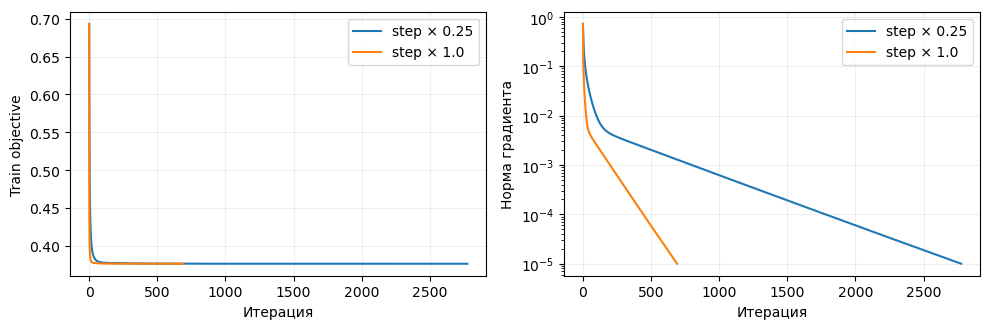

In [16]:
lr_result = run_logreg_experiment(Xtr, ytr, Xva, yva)

1. Сошлись ли два запуска к сопоставимому решению? Подтвердите ответ по истории и числам.
2. Насколько собственная модель согласуется с библиотечной? Объясните связь между `C`, $n$ и $\lambda$.
3. Как ваша реализация ведёт себя на больших по модулю логитах?

**Ответ:**
1) Да,сошлись. Это видно по значениям в train_ojb, valid_brier, valid_accuracy. Ну, и по графику тоже видно
2) Модель согласуется хорошо, только итераций требуется больше. C - это 1 / (n * $\lambda$).
3) Ведет стабильно(не переволняется)


## Собственное разбиение дерева

Сравним, как другой критерий неоднородности меняет разбиения и прогноз дерева.

Для бинарного узла $n_k$ — число объектов класса $k$, $n=n_0+n_1>0$,
$p_k=n_k/n$. Реализуйте назначенный критерий `impurity_counts`:

$$H_{\rm sqrt}=2\sqrt{p_0p_1},\qquad
H_{1.5}=2(1-p_0^{3/2}-p_1^{3/2}).$$

Варианты 1/2 используют `sqrt`, 3/4 — `tsallis15`.
Затем реализуйте `best_split`, максимизирующий

$$G=H(\mathrm{parent})-\frac{n_L}{n}H(L)-\frac{n_R}{n}H(R).$$

- Кандидаты — середины соседних **различных** значений каждого признака.
  Условие левого потомка: `X[:, feature] <= threshold`.
- Каждый потомок содержит не менее `min_leaf` **строк**, включая повторы.
  Если кандидатов нет или глобальный максимум $G_{\max}\le10^{-12}$,
  верните `None`.
- Среди **всех** кандидатов с $G\ge G_{\max}-10^{-12}$ выберите меньший индекс
  признака, затем меньший порог. Верните `Split(feature, threshold, gain)`.

**Варианты 1/3:** обязательна сложность $O(d\,n\log n)$ в одном узле.
**Варианты 2/4:** допустим любой корректный самостоятельный поиск,
в том числе $O(d\,n^2)$.
Нельзя делегировать весь поиск разбиения sklearn или готовому `brute_split`.
Рекурсия и обход дерева уже реализованы. Глубина не больше 5;
`min_leaf` для вариантов 1–4 равен 5, 10, 15, 20 соответственно.

In [ ]:
def impurity_counts(counts: FloatVector, kind: Criterion) -> float:
    """counts: два неотрицательных счётчика с положительной суммой."""
    counts = np.asarray(counts, dtype=float)
    n = counts.sum()
    if n == 0:
        return 0.0

    p0, p1 = counts[0] / n, counts[1] / n

    return 2.0 * (1.0 - p0 ** 1.5 - p1 ** 1.5)
    


def best_split(
    X: FloatMatrix, y: IntVector, min_leaf: int, kind: Criterion
) -> Split | None:
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    n = len(y)
    
    if n < 2 * min_leaf:
        return None
        
    parent_counts = np.bincount(y, minlength=2)
    parent_impurity = impurity_counts(parent_counts, kind)
    
    candidates = []

    for feature in range(X.shape[1]):

        values = np.unique(X[:, feature])
        
        for lower, upper in zip(values[:-1], values[1:]):
            threshold = float(lower / 2 + upper / 2)
            if threshold >= upper:
                threshold = float(np.nextafter(upper, lower))
                
            mask = X[:, feature] <= threshold
            left_n = int(mask.sum())
            right_n = n - left_n
            
            if min(left_n, right_n) < min_leaf:
                continue 
                
            left_h = impurity_counts(np.bincount(y[mask], minlength=2), kind)
            right_h = impurity_counts(np.bincount(y[~mask], minlength=2), kind)
            
            gain = parent_impurity - (left_n * left_h + right_n * right_h) / n
            
            candidates.append(Split(feature, threshold, float(gain)))
            
    if not candidates:
        return None
        
    maximum = max(split.gain for split in candidates)
    
    if maximum <= 1e-12:
        return None
        
    best_candidates = [s for s in candidates if s.gain >= maximum - 1e-12]
    
    best_candidates.sort(key=lambda s: (s.feature, s.threshold))
    
    return best_candidates[0]

In [18]:
tree_kind = TREE_SETTINGS[VARIANT]["criterion"]
print("H:", impurity_counts(np.array([3.0, 5.0]), tree_kind))
print(best_split(X_train[:30], ytr[:30], 3, tree_kind))

H: 0.5525089044255355
Split(feature=1, threshold=420.84669495, gain=0.42358428467454556)


,case,n,min_leaf,feature,threshold,passed
0,constant_features,8,2,NaN,NaN,True
1,too_few_rows,5,3,NaN,NaN,True
2,pure_node,8,2,NaN,NaN,True
3,duplicate_values,6,2,0.0,0.500000,True
4,feature_tie,4,1,0.0,1.500000,True
5,threshold_tie,6,1,0.0,0.500000,True
6,raw_row_counts,8,3,0.0,0.500000,True
7,min_leaf_blocks_split,6,3,NaN,NaN,True
8,random_0,27,2,0.0,-0.082256,True
9,random_1,32,3,0.0,0.500000,True


,n,own_ms,oracle_ms,same_split
0,60,4.0354,3.5018,True
1,120,11.2451,10.4876,True
2,240,24.9312,24.6547,True
3,480,58.0685,58.3071,True


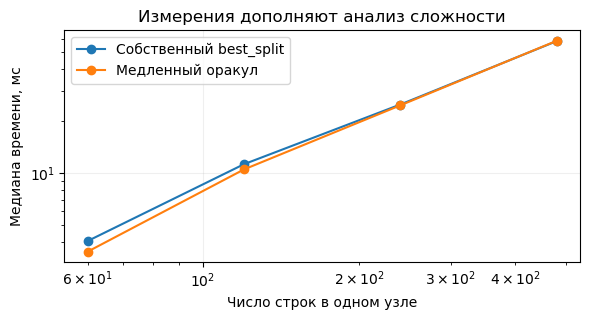

,model,accuracy,F1,depth,leaves,fit_ms
0,own tsallis15,0.844444,0.831325,5,16,230.7168
1,sklearn Gini,0.850000,0.840237,5,16,2.8244


Корень: MajorAxisLength ≤ 416.92486; gain=0.28488591


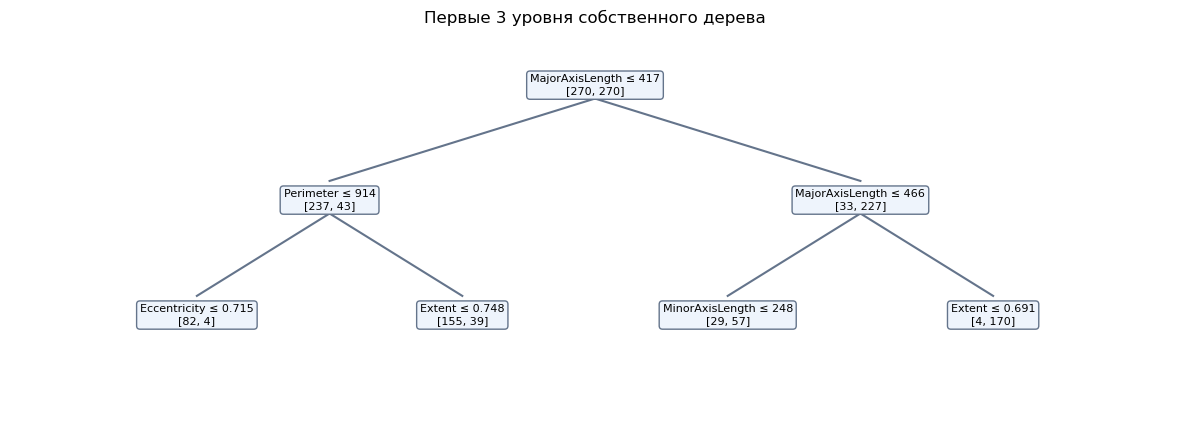

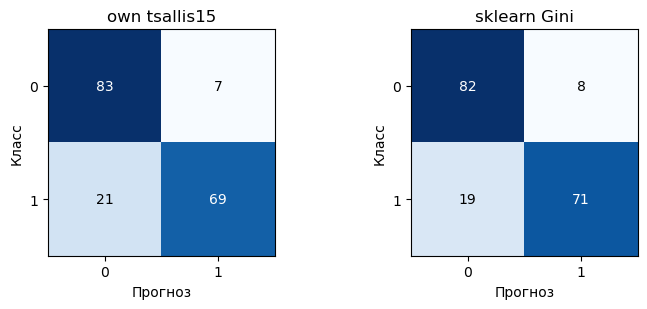

Пример ошибки: validation[2], y=1, прогноз=0, частоты листа=[84, 15]


In [19]:
tree_result = tree_experiment(X_train, ytr, X_valid, yva, VARIANT, FEATURES)

1. Обоснуйте сложность своего поиска **в одном узле** и сопоставьте с замерами.
   Какие операции вы выполняете для каждого признака и для каждого порога?
2. Разберите корневое разбиение и приведённую ошибку: какие частоты и значения
   признаков определили решение?
3. Объясните отличия от Gini при одинаковых глубине и min_leaf.
   Что проверяет совпадение с оракулом, если он вызывает ваш `impurity_counts`?

**Ответ:** …
1) Общая сложность - d * n ^ 2, где d - кол-во признаков, а n - кол-во объектов.
Для каждого признака мы находим уникальные , после берем кандитатов  из середен соседних признаков.
Для каждого порога мы смотрим количество элементов, которые меньше его. Затем считаем классы в левом и правом поддереве. Растем квадратично сложность
2) 

### Выборки строк и признаков


Реализуйте `draw_plan`. `rows` хранит **все** m индексов, включая повторы;
`inbag_count` — их целочисленная гистограмма длины n. `features` содержит q
различных отсортированных индексов из `0,...,d−1`. Строки выбираются с возвращением
при `replace=True` и без возвращения иначе; при `replace=False` нужно m≤n.
Используйте ровно переданные `rng_rows` и `rng_features` для своих двух выборок.

Пример: `rows=[0,0,2,4]` означает кратности `[2,0,1,0,1]` и OOB-индексы `[1,3]`.
Множество уникальных строк не заменяет bootstrap-выборку. В основных опытах
`m=ceil(sample_fraction*n)`, а признаки выбираются один раз на дерево.

Заглушки далее возвращают только структуру результата либо NaN; их smoke-проверки
намеренно не проходят до заполнения TODO.

In [ ]:
def draw_plan(
    n: int,
    d: int,
    m: int,
    q: int,
    replace: bool,
    rng_rows: np.random.Generator,
    rng_features: np.random.Generator,
) -> SamplePlan:
    # TODO: две выборки, сортировка признаков, точные кратности строк.
    return SamplePlan(
        rows=np.zeros(m, dtype=np.int64),
        features=np.arange(q, dtype=np.int64),
        inbag_count=np.zeros(n, dtype=np.int64),
    )

In [ ]:
plan_preview = draw_plan(
    8, 7, 6, 4, True, np.random.default_rng(7), np.random.default_rng(8)
)
print(plan_preview.rows, plan_preview.features, plan_preview.inbag_count)

In [ ]:
check_draw_plan()
sampling_preview = provided_sampling_preview(len(y_train), X_train.shape[1], VARIANT)
display(sampling_preview)

**Объясните по результату.** Почему повторы нельзя удалить до обучения? Какие изменения в плане допустимы при смене q, если seed и параметры строк фиксированы?


**Ответ:**

### Обучение своего bootstrap-ансамбля


Реализуйте `fit_ensemble`: вычислите m и q, для каждого `b=0,...,B−1` получите
`provided_rngs(seed,b)`, вызовите свою `draw_plan`, выберите `X[rows][:,features]`
и `y[rows]`, обучите один предоставленный адаптером член ансамбля
`provided_fit_member(X_sample,y_sample,plan,n_classes=K)` и сохраните все члены.
`provided_validate_training` проверяет входы и возвращает `(n,d,K,prior)`.

Адаптер использует `DecisionTreeClassifier` с Gini, `max_depth=5`,
`min_samples_leaf=5`, `random_state=0`; он не зависит от функции разбиения из
другого задания. Глобальный порядок классов — `0,...,K−1` полного train.
Bootstrap может потерять класс, но K столбцов прогноза должны сохраниться.
Адаптер листа использует готовую функцию
`provided_leaf_probability(counts, alpha, prior)`: она возвращает
`(counts + alpha * prior) / (counts.sum() + alpha)` в глобальном порядке классов.
В главном опыте `alpha=2` — общая масса равномерного prior.
Реализация и доказательство этой формулы не требуются.

Готовые потоки `SeedSequence([seed,b,0])` и `SeedSequence([seed,b,1])` обеспечивают
одинаковые первые деревья при смене B и одинаковые планы строк при смене q.

In [ ]:
def fit_ensemble(
    X: FloatArray, y: IntArray, config: BaggingConfig, n_estimators: int, seed: int
) -> Ensemble:
    n, d, K, prior = provided_validate_training(X, y, config)
    members: list[TreeMember] = []
    # TODO: собственный цикл по деревьям, планы и обучение готового дерева.
    return Ensemble(
        members=members,
        config=config,
        n_classes=K,
        n_features_in=d,
        n_train=n,
        seed=seed,
        prior=prior,
    )

In [ ]:
preview_config = provided_variant_settings(VARIANT, X_train.shape[1])[0].config
small_ensemble = fit_ensemble(X_train, y_train, preview_config, 4, 2026)
print(len(small_ensemble.members), small_ensemble.n_classes)

In [ ]:
check_ensemble()

**Объясните по результату.** Почему независимые новые ансамбли для каждого B мешают оценить именно добавление деревьев? Как адаптер сохраняет вероятность класса, отсутствующего в конкретном bootstrap?


**Ответ:**

### Вероятности каждого дерева


Реализуйте `predict_members(model,X) -> (B,n,K)`. Используйте
`provided_member_proba(member,X,model.config.alpha,model.prior)` и сохраните
порядок членов ансамбля. Адаптер сам выбирает признаки дерева и вызывает готовую
`provided_leaf_probability` для каждого встретившегося листа. Вход X всегда содержит исходные d признаков.
Пустой набор объектов должен давать форму `(B,0,K)`.

In [ ]:
def predict_members(model: Ensemble, X: FloatArray) -> FloatArray:
    # TODO: прогноз каждого члена и объединение по оси B.
    return np.full(
        (len(model.members), len(X), model.n_classes), np.nan, dtype=np.float64
    )

In [ ]:
P_preview = predict_members(small_ensemble, X_valid[:5])
print(P_preview.shape)

In [ ]:
check_predict_members()

**Объясните по результату.** Что обозначает каждая ось массива? Почему глобальный K нельзя заменять числом классов внутри отдельной bootstrap-выборки?


**Ответ:**

### Soft и hard на одних прогнозах


Реализуйте `aggregate_predictions(probabilities,mode) -> (n,K)` для общего K≥2.
Soft усредняет векторы вероятностей по деревьям. Hard сначала превращает
решение **каждого дерева** в one-hot-вектор, затем усредняет голоса.
При любой ничьей `argmax` выбирает меньший индекс класса. В binary это класс 1
только при вероятности строго больше 0.5.

Выход hard — **доли голосов**, по которым тоже вычисляется Brier. Для смены
агрегации переобучение и новый seed не нужны. Проверку формы и распределений
можно выполнить готовой `provided_validate_probabilities`.

In [ ]:
def aggregate_predictions(probabilities: FloatArray, mode: Aggregation) -> FloatArray:
    # TODO: средние вероятности либо средние one-hot-голоса.
    return np.full(probabilities.shape[1:], np.nan, dtype=np.float64)

In [ ]:
print("Soft:", aggregate_predictions(P_preview, "soft"))
print("Hard:", aggregate_predictions(P_preview, "hard"))

In [ ]:
check_aggregation()

**Объясните по результату.** Почему итоговые классы soft и hard могут совпасть, а Brier различаться? В каком месте обработки hard теряются исходные вероятности?


**Ответ:**

### M2. Brier и разнообразие ансамбля

Хотим отделить качество отдельных деревьев от эффекта их усреднения и получить численную проверку для OOB.
Обозначения: $B$ — число деревьев, $K$ — число классов, $C$ — оцениваемые объекты; $p_{bi}$ — распределение дерева $b$ для объекта $i$, $e_{y_i}$ — one-hot истинного класса.

Для непустого набора C и вероятностей $p_{bi}\in\mathbb R^K$ используем
$\operatorname{BS}(y_i,p)=\frac12\|p-e_{y_i}\|^2$.
Пусть $w_{ib}\ge0$, $\sum_b w_{ib}=1$, а $\bar p_i=\sum_b w_{ib}p_{bi}$.
Докажите конечное взвешенное тождество

$$
\underbrace{\frac1{|C|}\sum_{i\in C}\sum_b w_{ib}
\operatorname{BS}(y_i,p_{bi})}_{I}
-
\underbrace{\frac1{|C|}\sum_{i\in C}\operatorname{BS}(y_i,\bar p_i)}_{E}
=
\underbrace{\frac1{2|C|}\sum_{i\in C}\sum_b w_{ib}
\|p_{bi}-\bar p_i\|^2}_{D}.
$$

Раскройте квадрат $p_{bi}-e_{y_i}=(p_{bi}-\bar p_i)+(\bar p_i-e_{y_i})$ и явно
объясните исчезновение смешанного члена. Получите равные веса $1/B$ как частный
случай; объясните, почему при K=2 нормировка совпадает с $(p_1-y)^2$.
Что из $E=I-D$ следует для среднего индивидуального Brier, лучшего дерева и accuracy?
Нужна ли здесь независимость моделей?

Для OOB обозначьте $a_{ib}=1$ только если объект i отсутствует в обучающей выборке
дерева b, $c_i=\sum_b a_{ib}$ и $C_B=\{i:c_i>0\}$. Перенесите доказательство на
$w_{ib}=a_{ib}/c_i$ и усредняйте **объекты** из $C_B$ с равными весами.
Объясните, почему среднее отдельных OOB-ошибок деревьев не заменяет I.

**Ваш вывод M2:**

Запишите доказательство, область применимости и ответы на вопросы.

### Реализация взвешенного разложения M2


Реализуйте `brier_decomposition(y,probabilities,weights)` и верните тройку
`(individual,ensemble_score,diversity) = (I,E,D)`. Вероятности имеют форму `(B,n,K)`.
Веса формы `(B,)` общие для объектов; веса `(B,n)` могут зависеть от объекта.
В каждом столбце сумма весов равна единице. Некорректные веса отклоняйте, а не
исправляйте скрытой нормировкой; доступны готовые `provided_validate_weights`,
`provided_validate_probabilities` и `provided_validate_labels`.

Все три члена должны использовать одинаковые объекты, вероятности и веса.
Для hard сначала передайте сюда one-hot-решения деревьев. Не вычисляйте
разнообразие как разность I−E: реализуйте его формулу независимо, чтобы невязка
проверяла вычисления. Контроль для равных весов: I=0.125, E=0.100, D=0.025;
для объектных OOB-весов из примера: I=0.105, E=0.085, D=0.020.

In [ ]:
def brier_decomposition(
    y: IntArray, probabilities: FloatArray, weights: FloatArray
) -> tuple[float, float, float]:
    # TODO: три независимых вычисления по формулам M2.
    return float("nan"), float("nan"), float("nan")

In [ ]:
P_example = np.array([[[0.8, 0.2], [0.3, 0.7]], [[0.4, 0.6], [0.1, 0.9]]])
print(brier_decomposition(np.array([0, 1]), P_example, np.array([0.5, 0.5])))

In [ ]:
check_brier_decomposition()
provided_show_brier_example()

**Объясните по результату.** Какие веса соответствуют обычному valid-усреднению и OOB-усреднению? Почему большее разнообразие само по себе не определяет лучший режим?


**Ответ:**

### Формулы M2 для собственного OOB-аккумулятора

В одном проходе по деревьям храните для каждого train-объекта
$c_i=\sum_b a_{ib}$, $S_i=\sum_b a_{ib}p_{bi}$,
$L_i=\sum_b a_{ib}\operatorname{BS}(y_i,p_{bi})$ и
$Q_{ik}=\sum_b a_{ib}p_{bik}^2$.
На покрытых объектах:

$$
\bar p_i=S_i/c_i,\quad I=\operatorname{mean}_{i\in C_B}(L_i/c_i),\quad
E=\operatorname{mean}_{i\in C_B}\tfrac12\|\bar p_i-e_{y_i}\|^2,
$$
$$
D=\tfrac12\operatorname{mean}_{i\in C_B}\sum_k
\left(Q_{ik}/c_i-\bar p_{ik}^2\right).
$$

Для hard в эти суммы входят one-hot-решения деревьев.
Именно эти четыре аккумулятора нужны в следующей функции; плотный массив
всех `(B,n_train,K)` прогнозов для неё не нужен.

### OOB-прогнозы и снимки префиксов


Реализуйте `oob_prefixes(model,X,y,prefixes,mode) -> list[OOBState]`.
X и y — исходный train в исходном порядке. `prefixes` — строго возрастающий
кортеж положительных B, не превышающих размер ансамбля. Для дерева допускаются
только строки, где `member.plan.inbag_count == 0`. Получайте вероятности через
`provided_member_proba` и обновляйте собственные четыре аккумулятора из M2.

На каждом запрошенном B сохраните `OOBState`: `counts`, `sum_proba`,
`sum_individual_brier`, `sum_squared_proba`, `probabilities`, три средних M2,
а также `prefix` и `mode`. Все массивы каждого снимка — независимые копии.
В `probabilities` непокрытые строки остаются NaN. Если покрытых объектов нет,
все три средних — NaN. В OOB-метриках каждому покрытому объекту соответствует
один вес, независимо от числа его голосов. Не усредняйте ошибки деревьев.

Рабочая память помимо снимков — O(nK), накопление — O(BnK). Деревья заново не обучаются.
При m=n без возвращения OOB-покрытие равно нулю, даже со случайными признаками.

In [ ]:
def oob_prefixes(
    model: Ensemble,
    X: FloatArray,
    y: IntArray,
    prefixes: tuple[int, ...],
    mode: Aggregation,
) -> list[OOBState]:
    n, K = model.n_train, model.n_classes
    # TODO: собственное накопление и копии состояния для всех prefixes.
    # Ниже только один структурный образец; NaN не является оценкой ошибки.
    return [
        OOBState(
            prefix=prefixes[0],
            mode=mode,
            counts=np.zeros(n, dtype=np.int64),
            sum_proba=np.zeros((n, K), dtype=np.float64),
            sum_individual_brier=np.zeros(n, dtype=np.float64),
            sum_squared_proba=np.zeros((n, K), dtype=np.float64),
            probabilities=np.full((n, K), np.nan, dtype=np.float64),
            individual_brier=float("nan"),
            ensemble_brier=float("nan"),
            diversity=float("nan"),
        )
    ]

In [ ]:
preview_oob = oob_prefixes(small_ensemble, X_train, y_train, (1, 4), mode="soft")
print([(state.prefix, state.n_covered) for state in preview_oob])

In [ ]:
check_oob_prefixes()
display(provided_oob_table(preview_oob))

**Объясните по результату.** Почему нельзя заполнить непокрытые строки prior или прогнозом in-bag дерева? Почему сравнение OOB Brier при малых B включает изменение состава оцениваемых объектов?


**Ответ:**

**Справка к coverage, без отдельного вывода.** Вероятность OOB для одного объекта
и одного дерева равна $q_{\rm OOB}=(1-1/n)^m$ с возвращением и $q_{\rm OOB}=1-m/n$
без возвращения. При независимых выборках деревьев
$\mathbb E[c_i]=Bq_{\rm OOB}$ и
$\mathbb E[\mathrm{coverage}]=1-(1-q_{\rm OOB})^B$.

### Назначенное сравнение A1–A4

Все реализованные функции одинаковы для вариантов 1–4. Запустите только строку
своего варианта; готовый `experiment` выбирает её по VARIANT. В нём 64 дерева и
префиксы 1, 4, 16, 64; все деревья получают исходные семь признаков либо выбранные
четыре. Параметры дерева и готового расчёта вероятностей листа одинаковы во всех режимах.

| Вариант | Единственное обязательное сравнение |
|---|---|
| A1 | Доля строк 0.6 против 1.0; с возвращением, все 7 признаков, soft |
| A2 | С возвращением против без возвращения; доля 0.6, все 7 признаков, soft |
| A3 | Все 7 признаков против случайных 4 один раз на дерево; с возвращением, доля 1.0, soft |
| A4 | Soft против hard на одних и тех же 64 деревьях; с возвращением, доля 1.0, случайные 4 признака |

Готовый отчёт показывает valid/OOB Brier, accuracy, покрытие и все три члена M2.
Выбор режима и B делается по минимуму valid Brier; значения в пределах `1e-12`
считаются равными, затем выбираются меньший B и первый режим таблицы.
Результат `ensemble_result` сохраняет модели, вероятности, OOB-снимки, таблицы и
выбранную конфигурацию для финального test и дополнительного опыта.

In [ ]:
ensemble_result = experiment(X_train, y_train, X_valid, y_valid, VARIANT)
show_ensemble_report(ensemble_result)

**Интерпретация своего варианта.**

- **A1:** свяжите долю строк с кратностями, числом уникальных объектов и ранним OOB-покрытием. Как изменились I и D?
- **A2:** сопоставьте строки без возвращения с bootstrap; какой механизм меняет состав обучающей выборки и доступность OOB-голосов?
- **A3:** подтвердите совпадение планов строк при смене числа признаков. Что изменилось в индивидуальной ошибке и разнообразии?
- **A4:** подтвердите, что использовались одни деревья. Сравните вероятности, Brier и accuracy; поясните, почему разложения soft и hard относятся к разным исходным векторам.

Назовите выбранные режим и B. Оцените согласие valid и OOB с учётом coverage.
Для общего вывода используйте также LR и одиночное дерево из соседних блоков;
окончательная оценка на test выполняется отдельной финальной ячейкой.


**Ответ:**

## SVM и ядра

Линейный классификатор выдаёт score $s_i=w^\top x_i+b$. Предсказание равно `int(score > 0)`.
Для меток $y_i\in\{0,1\}$ введём $t_i=2y_i-1$ и **отступ** $m_i=t_i s_i$.
В этом блоке сравниваются две функции потерь на тех же стандартизованных train и validation.

Все четыре задания выполняются в каждом варианте. Параметры выдаёт готовый `svm_config(VARIANT)`:

| Вариант | $\delta$ | $\lambda$ | Остановка | `max_iter` | `gamma_focus` |
|---|---:|---:|---|---:|---:|
| 1 | 0.25 | 0.02 | `gradient` | 8000 | 0.01 |
| 2 | 0.5 | 0.05 | `window` | 3000 | 0.1 |
| 3 | 1 | 0.1 | `gradient` | 3000 | 1 |
| 4 | 1.5 | 0.2 | `window` | 3000 | 10 |

### S1. Потери отдельных объектов

Задача loss — назначить штраф каждому score с учётом правильного класса. Положим $z=1-m$:

\[
\ell_{sq}(m)=\max(0,1-m)^2,\qquad
\ell_\delta(m)=\begin{cases}
0,&z\le0,\\
z^2/(2\delta),&0<z<\delta,\\
z-\delta/2,&z\ge\delta.
\end{cases}
\]

Реализуйте **обе** loss. `margin_loss_grad` возвращает два вектора длины $n$:
потери объектов и производные **по score** $s_i$, без усреднения.
Запишите производные в ответе под графиками; учтите переход от $m_i$ к $s_i$.

In [ ]:
def margin_loss_grad(
    scores: FloatVector, y: IntVector, kind: LossKind, delta: float
) -> tuple[FloatVector, FloatVector]:
    """Return per-object losses and d(loss_i)/d(score_i), both shape (n,)."""
    # TODO: замените заготовку реализацией обеих loss.
    shape = np.asarray(scores).shape
    return np.zeros(shape, dtype=float), np.zeros(shape, dtype=float)

In [ ]:
losses, derivatives = margin_loss_grad(
    np.array([-0.5, 0.2, 1.5]),
    np.array([0, 1, 1]),
    "huber_hinge",
    svm_config(VARIANT).delta,
)
print(losses, derivatives)

In [ ]:
display(smoke_margin_loss(VARIANT))
svm_loss_curves = run_margin_loss_experiment(VARIANT)

**Ответ S1.** Запишите $\partial\ell/\partial s_i$ для обеих loss.
Выберите в `svm_loss_curves` три отступа: в линейном участке Huber, в его квадратичном участке и больше 1.
Приведите значения потерь и производных. Как эти точки представлены на ваших графиках?

**Ответ:** …

### S2. Цель всей выборки и её градиент

Для обучения нужно объединить потери объектов и штраф за величину весов:

\[
J(w,b)=\frac1n\sum_{i=1}^n\ell\!\left(t_i(w^\top x_i+b)\right)+\frac{\lambda}{2}\|w\|^2.
\]

`theta = [w, b]` имеет длину $d+1$. Реализуйте значение $J$ и полный градиент по `theta`,
используя `margin_loss_grad`. Последний параметр $b$ **не регуляризуется**.
Готовая проверка сопоставляет ненулевой числовой пример и finite differences на train.

In [ ]:
def svm_objective_grad(
    X: FloatMatrix,
    y: IntVector,
    theta: FloatVector,
    l2: float,
    kind: LossKind,
    delta: float,
) -> tuple[float, FloatVector]:
    """Return regularized mean loss J and its gradient with respect to [w,b]."""
    # TODO: используйте свою margin_loss_grad и соберите градиент по [w,b].
    return 0.0, np.zeros_like(np.asarray(theta, dtype=float))

In [ ]:
value, gradient = svm_objective_grad(
    Xtr[:4], ytr[:4], np.zeros(Xtr.shape[1] + 1), 0.1, "squared_hinge", 0.5
)
print(value, gradient.shape)

In [ ]:
display(smoke_svm_objective(VARIANT))
svm_gradient_check = check_svm_objective(Xtr, ytr, VARIANT)

**Ответ S2.** Запишите компоненты градиента по $w$ и $b$.
Из `svm_gradient_check` приведите `analytic`, `numeric` и `abs_error` для одной координаты веса и для $b$.
Как отдельно проверяется отсутствие штрафа на свободный член? Почему одного совпадения finite differences недостаточно для проверки самой постановки $J$?

**Ответ:** …

### S3. Обучение и остановка

Нужно подключить вашу цель к готовому `provided_gd` и решить, когда завершить его работу.
Сам цикл градиентного спуска уже дан. Он принимает `objective(theta) -> (J, gradient)`,
начальные параметры, шаг и лимит обновлений; `stop_rule(history)` **заменяет** стандартную остановку по градиенту.

Запись `Epoch` содержит `step`, `theta`, `objective`, `grad_norm`. История включает начальную точку.
Результат `FitResult` содержит `theta`, `history`, `reason`: `stop_rule`, `gradient` или `max_iter`.
`StopConfig` задаёт `grad_tol=1e-5`, `rel_tol=1e-8`, `patience=5`, `guard_tol=1e-3`.

Реализуйте оба режима `should_stop`; основной запуск использует режим вашего варианта:

- `gradient`: последняя норма полного градиента не больше `grad_tol`.
- `window`: есть хотя бы `patience + 1` записей; для **каждой** из последних `patience` пар
  $(J_{j-1},J_j)$ одновременно выполнены
  $0\le J_{j-1}-J_j\le\texttt{rel_tol}\max(1,|J_{j-1}|)$ и
  $\|\nabla J_j\|\le\texttt{guard_tol}$.

В `fit_svm` задайте нулевой вектор `[w,b]`, вашу `svm_objective_grad` и callback `should_stop`.
Шаг равен `margin_step(X, l2, kind, delta) * step_scale`; этот помощник дан готовым.
Верните результат `provided_gd`. Validation и test в остановке не используются.

Эксперимент сравнит обе loss с готовым L-BFGS-B на той же вашей цели.
Для `LinearSVC` используются `loss="squared_hinge"`, `C=1/(n*l2)`, `intercept_scaling=100`;
его $J$ и норма градиента также пересчитываются через вашу цель.

In [ ]:
def should_stop(history: Sequence[Epoch], config: StopConfig) -> bool:
    """Apply the selected stopping rule to recorded training iterations."""
    # TODO: реализуйте режимы gradient и window.
    return False


def fit_svm(
    X: FloatMatrix,
    y: IntVector,
    l2: float,
    kind: LossKind,
    delta: float,
    stop: StopConfig,
    max_iter: int,
    step_scale: float = 1.0,
) -> FitResult:
    """Fit the student's SVM objective through the ready provided_gd."""
    # TODO: подключите цель, начальные параметры, шаг и callback остановки.
    theta = np.zeros(np.asarray(X).shape[1] + 1, dtype=float)
    history = [record(0, theta, 0.0, np.zeros_like(theta))]
    return FitResult(theta=theta, history=history, reason="stub")

In [ ]:
cfg = svm_config(VARIANT)
small_svm = fit_svm(Xtr[:6], ytr[:6], cfg.l2, "huber_hinge", cfg.delta, cfg.stop, 3)
print(
    small_svm.theta.shape,
    len(small_svm.history),
    should_stop(small_svm.history, cfg.stop),
)

In [ ]:
display(smoke_svm_training(VARIANT))
svm_result = run_svm_experiment(Xtr, ytr, Xva, yva, VARIANT)

**Ответ S3.** Используйте объекты из `svm_result`:

1. Для каждой loss приведите `J`, норму градиента, шаг и `reason` из `metrics_table`.
   Сопоставьте с L-BFGS-B и `LinearSVC`. Какие проверки помогут объяснить наблюдаемые различия?
2. В `stop_history` найдите два шага, на которых изменение $J$ и изменение validation accuracy различаются по поведению.
   Если такого примера нет, приведите проверенные шаги. Что показывает правило остановки вашего варианта?
3. Сравните три строки `step_table`. Как связаны шаг, изменение $J$, градиент и причина завершения?
   Выберите два `validation_row` из `object_table`, приведите их score, отступ и предсказание для обеих loss.

**Ответ:** …

### S4. RBF и score по опорным объектам

Ядро задаёт сходство пары объектов. В этом задании коэффициенты обучает готовый `SVC`,
а вы вычисляете матрицу сходств и восстанавливаете итоговый score:

\[
K_{ij}=\exp(-\gamma\|x_i-z_j\|^2),\qquad
s(x)=\sum_{j\in SV}\texttt{dual\_coef}_j K(x,x_j)+b.
\]

`rbf_kernel(X, Z, gamma)` возвращает матрицу формы `(len(X), len(Z))`.
`K_to_train` содержит столбцы **всех** train-объектов в исходном порядке.
`support_indices` выбирает нужные столбцы; `dual_coef` уже включает знак класса и соответствует этому порядку.
`kernel_scores` возвращает вектор score; предсказание снова равно `score > 0`.

Готовый эксперимент использует $\gamma\in\{0.01,0.1,1,10\}$ и $C=1$.
`best_gamma` выбирается по validation accuracy, при равенстве — меньший $\gamma$.
Для сравнения даны `LinearSVC(loss="hinge")`, `SVC(kernel="linear")` и RBF на тех же признаках и разбиении при $C=1$.
Границы строятся после отдельного обучения на двух признаках. Test в выборе $\gamma$ не участвует.

In [ ]:
def rbf_kernel(X: FloatMatrix, Z: FloatMatrix, gamma: float) -> FloatMatrix:
    """Return the RBF matrix with shape (len(X), len(Z))."""
    # TODO: вычислите попарные квадраты расстояний и значения ядра.
    return np.zeros((len(X), len(Z)), dtype=float)


def kernel_scores(
    K_to_train: FloatMatrix,
    support_indices: IntVector,
    dual_coef: FloatVector,
    intercept: float,
) -> FloatVector:
    """Return one binary score per row; dual_coef already includes class signs."""
    # TODO: выберите столбцы опорных объектов и восстановите score.
    return np.zeros(len(K_to_train), dtype=float)

In [ ]:
K_preview = rbf_kernel(Xtr[:2], Xtr[:3], 0.1)
print(
    K_preview.shape,
    kernel_scores(K_preview, np.array([0, 2]), np.array([0.5, -0.5]), 0.1),
)

In [ ]:
display(smoke_svm_kernel())
kernel_result = run_svm_kernel_experiment(
    Xtr, ytr, Xva, yva, VARIANT, pair=(1, 2), feature_names=FEATURES
)

**Ответ S4.** Используйте `kernel_result`:

1. Сопоставьте `gamma_focus` с `neighbor_gamma` по train/validation accuracy, числу опорных объектов,
   невязкам ядра и score из `kernel_table`. Какой `best_gamma` выбран и по каким значениям?
2. В `object_table` найдите два `validation_row`, у которых изменилось предсказание между этими $\gamma$.
   Приведите истинный класс и оба score. Если таких объектов меньше двух, разберите все найденные и один с малым абсолютным score.
3. Сравните готовые линейные модели и RBF по `controlled_table` и двумерным границам.
   Какие условия сравнения совпадают? Какие наблюдения по двум признакам можно проверить на модели со всеми признаками?

**Ответ:** …

## Устойчивость к шуму в train — варианты 1 и 3

Вариант 1: доли $0,\ 0.025,\ 0.05$; вариант 3: $0,\ 0.05,\ 0.10$.
Для каждой доли используйте seeds `101, 202, 303`. Validation остаётся прежним.

Реализуйте `corrupt_labels`: поменяйте $0\leftrightarrow1$ у
$\lfloor\text{fraction}\cdot n\rfloor$ объектов и верните копию меток и булеву маску.
При одном seed множества изменённых объектов должны быть вложены при росте доли.

In [ ]:
def corrupt_labels(
    y: NDArray[np.int64], fraction: float, seed: int
) -> tuple[NDArray[np.int64], NDArray[np.bool_]]:
    # TODO
    return np.asarray(y, dtype=np.int64).copy(), np.zeros(len(y), dtype=bool)

In [ ]:
if VARIANT in (1, 3):
    noisy_y, changed = corrupt_labels(ytr, 0.05, 101)
    print(noisy_y.shape, changed.dtype, int(changed.sum()))

Реализуйте цикл исследования `training_stability_report`.
`fit_predict(y_changed)` обучает LR, одиночное дерево и выбранный ансамбль
и возвращает словарь вероятностей на validation. Параметры и планы ансамбля зафиксированы на чистом train.

Для каждой модели, seed и доли верните строку с полями:
`seed`, `fraction`, `n_changed`, `model`, `brier`, `delta_brier`,
`mean_abs_shift`, `changed_labels`.

Здесь `delta_brier` — изменение относительно чистого train;
`mean_abs_shift` — среднее изменение вероятности класса 1;
`changed_labels` — доля изменившихся решений. При нулевой доле используйте чистый результат.
Изменяйте обучающие метки перед переобучением.

In [ ]:
def training_stability_report(
    y_train: NDArray[np.int64],
    fractions: Sequence[float],
    seeds: Sequence[int],
    fit_predict: Callable[[NDArray[np.int64]], dict[str, NDArray[np.float64]]],
    y_valid: NDArray[np.int64],
) -> pd.DataFrame:
    # TODO
    return pd.DataFrame(
        columns=[
            "seed",
            "fraction",
            "n_changed",
            "model",
            "brier",
            "delta_brier",
            "mean_abs_shift",
            "changed_labels",
        ]
    )

In [ ]:
if VARIANT in (1, 3):
    noise_predictor = make_noise_predictor(X_train, Xtr, X_valid, Xva, ensemble_result)
    display(training_stability_report(ytr, (0.0,), (101,), noise_predictor, yva))

In [ ]:
if VARIANT in (1, 3):
    noise_result = run_noise_extension(
        X_train, ytr, Xtr, X_valid, yva, Xva, ensemble_result, VARIANT
    )

1. Какая модель сильнее изменила вероятности, а какая — решения? Приведите числа для своего диапазона шума.
2. Что сохранялось между чистым и испорченным train и зачем? Как это связано с разбросом по seed?
3. Подтверждается ли преимущество ансамбля для всех долей и показателей? Укажите наблюдение, которое ограничивает ваш вывод.

**Ответ:**

## Ветка softmax · только варианты 2 и 4

В Dry Bean семь классов. Общая нормировка softmax позволяет получить одно
распределение вероятностей и обучать классы совместно через cross-entropy.
Сравните эту модель с multinomial и схемой One-vs-Rest (OvR).

Обозначения: $X\in\mathbb R^{n\times d}$, $W\in\mathbb R^{d\times K}$,
$b\in\mathbb R^K$, $y_i\in\{0,\ldots,K-1\}$, $S=XW+\mathbf1b^\top$.
Столбец W отвечает одному классу, строка S — одному объекту.
Пусть $T_{ik}=\mathbf1\{y_i=k\}$ — индикатор истинного класса.

$$P_{ik}=\frac{e^{S_{ik}}}{\sum_j e^{S_{ij}}},\qquad
J(W,b)=-\frac1n\sum_i\log P_{i,y_i}+\frac\lambda2\|W\|_F^2.$$

Выведите производную loss по logits, затем градиенты по W и b.
Реализуйте `softmax_probabilities` и `softmax_objective_grad`, возвращающую
`(J, dW, db)` форм `(scalar, (d,K), (K,))`. Свободный член b не штрафуется.
Вероятности и loss должны быть устойчивы при больших конечных logits:
используйте строчный сдвиг и log-sum-exp, без отсечения вероятностей в loss.

Обучение уже готово и использует общий `provided_gd` из SVM.
Параметр lambda равен 0.02 в варианте 2 и 0.2 в варианте 4;
библиотечное сравнение задаёт `C = 1 / (n * lambda)`.
Эксперимент использует 1260 train и 420 validation Dry Bean.

**Вывод градиента:** …

**Ответ:**

In [ ]:
def softmax_probabilities(scores: FloatMatrix) -> FloatMatrix:
    """scores: (n,K); верните вероятности (n,K), нормированные по строкам."""
    # TODO: реализуйте устойчивый softmax.
    return np.zeros_like(np.asarray(scores, dtype=float))


def softmax_objective_grad(
    X: FloatMatrix, y: IntVector, W: FloatMatrix, b: FloatVector, l2: float
) -> tuple[float, FloatMatrix, FloatVector]:
    """X: (n,d), y: (n,), W: (d,K), b: (K,); верните J, dW, db."""
    # TODO: реализуйте устойчивую среднюю loss и собственные градиенты.
    return (
        0.0,
        np.zeros_like(np.asarray(W, dtype=float)),
        np.zeros_like(np.asarray(b, dtype=float)),
    )

In [ ]:
if VARIANT in (2, 4):
    print(softmax_probabilities(np.array([[1000.0, 1001.0, -1000.0]])))
    print(
        softmax_objective_grad(
            BXtr[:8], Bytr[:8], np.zeros((16, 7)), np.zeros(7), SOFTMAX_L2[VARIANT]
        )[0]
    )

In [ ]:
if VARIANT in (2, 4):
    softmax_result = softmax_experiment(BXtr, Bytr, BXva, Byva, VARIANT, BEAN_CLASSES)

1. Почему общий сдвиг logits не меняет результат? Что проверяют большие logits
   и центральные разности и почему одной проверки accuracy недостаточно?
2. Сопоставьте J, норму градиента и причину остановки с результатом multinomial.
   Объясните связь C, n и lambda и возможное несовпадение вероятностей.
3. Выберите пару часто путаемых классов и сравните ошибки softmax и OvR.
   Как этот результат согласуется с log-loss, Brier_K и macro F1?

**Ответ:** …

## Итоговое сравнение

Выбор ансамбля уже записан в `ensemble_result["selection"]`: минимум validation Brier;
при равенстве до $10^{-12}$ — меньшее $B$, затем первый режим в таблице варианта.
Для RBF используется `kernel_result["best_gamma"]`.

Зафиксируйте выбранные параметры и объясните выбор по validation и OOB.
Затем установите `RUN_FINAL_TEST = True` и выполните финальную ячейку.
После просмотра test параметры не пересматриваются.

**Выбор и обоснование:**

In [ ]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    final_result = final_comparison(
        R,
        D,
        lr_result,
        tree_result,
        ensemble_result,
        svm_result,
        kernel_result,
        softmax_result,
    )

1. Какие выводы по validation сохранились на test, а какие изменились? Приведите значения метрик.
2. Какие показатели в итоговой таблице можно сравнить для всех моделей? Что потребовалось бы для заполнения остальных столбцов?
3. Выберите один фрагмент своего кода: объясните алгоритм, его сложность и причину выбранной реализации.
   Укажите ограничение вашего исследования и эксперимент, которым его можно проверить.

**Ответ:**

### Источники данных

- [UCI Raisin](https://archive.ics.uci.edu/dataset/850/raisin): Çınar, Köklü, Taşdemir; DOI [10.24432/C5660T](https://doi.org/10.24432/C5660T).
- [UCI Dry Bean](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset): Köklü, Özkan; DOI [10.24432/C50S4B](https://doi.org/10.24432/C50S4B).

Исходные CSV входят в комплект. Лицензия данных — CC BY 4.0.